# Normalizing Flows: RealNVP

This notebook presents multi-scale RealNVP models trained on MNIST and Fashion-MNIST. Four experiments compared model capacity and learned channel mixing. The saved results include validation and test metrics, learning curves, and images generated by reversing the flow.


In [ ]:
import gzip, json, math, random, struct, time, urllib.request
from datetime import datetime, timezone
from functools import lru_cache
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, Subset, random_split
from IPython.display import display, Markdown

SEED = 42
ACTIVE_DATASETS = ['mnist', 'fashion_mnist']
EPOCHS = 40
LEARNING_RATE = 2e-4
BATCH_SIZE = 128
SMOKE_TEST = False  # Debugging only: never submit smoke metrics as final results.
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ROOT = Path.cwd()
if (ROOT/'HW1'/'HW1.ipynb').exists(): ROOT = ROOT/'HW1'
LOCAL = ROOT.parent/'.local'/'hw1'
DATA_DIR = LOCAL/'data'
OUT = ROOT/'results'
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
REPORT = OUT/('smoke' if SMOKE_TEST else 'full')/RUN_ID
REPORT.mkdir(parents=True,exist_ok=True)
CHECKPOINTS = LOCAL/'checkpoints'/RUN_ID
CHECKPOINTS.mkdir(parents=True,exist_ok=True)
def seed_all(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_all()
print('Device:',DEVICE,'| PyTorch:',torch.__version__)
if DEVICE.type=='cuda': print('GPU:',torch.cuda.get_device_name(0))
else: print('CPU selected: these full experiments will be slow; use a CUDA PyTorch kernel.')
print('Report directory:',REPORT)

environment=dict(torch=str(torch.__version__),numpy=np.__version__,pandas=pd.__version__,device=str(DEVICE))
(REPORT/'environment.json').write_text(json.dumps(environment,indent=2))

Device: cuda | PyTorch: 2.11.0+cu128
GPU: NVIDIA GeForce RTX 4070
Report directory: c:\Users\Admin\Desktop\GEN_AI_CV\HW1\results\full\20261112T152734929186Z


90

## 1. Data, preprocessing and metrics

Each official training set was divided into 50,000 training and 10,000 validation images with a fixed seed. Labels were not used. Test evaluation followed validation-based model selection. These datasets had also been inspected during earlier development, so they are not a completely untouched benchmark.

Integer pixels were converted to continuous values using uniform dequantization:
$u=(k+\epsilon)/256$, where $\epsilon\sim U[0,1)$. The logit transform used $v=\alpha+(1-2\alpha)u$, $\alpha=0.05$, and $y=\log v-\log(1-v)$. The density included the preprocessing Jacobian:

$$\log p_U(u)=\log p_Z(f(y))+\log|\det J_f(y)|+\sum_i[\log(1-2\alpha)-\log v_i-\log(1-v_i)].$$

Results are reported as negative log-likelihood (NLL) in nats/image and bits per dimension:

$$\mathrm{bpd}=\frac{-\log p_U+784\log256}{784\log2}.$$

Lower values are better. Bpd is a dequantization bound rather than exact discrete likelihood. Continuous NLL can be negative. Validation noise was fixed for repeatable comparisons. Out-of-range generated pixels were clipped only for display, and their fraction was recorded. No thresholding, cropping or edge extraction was applied.


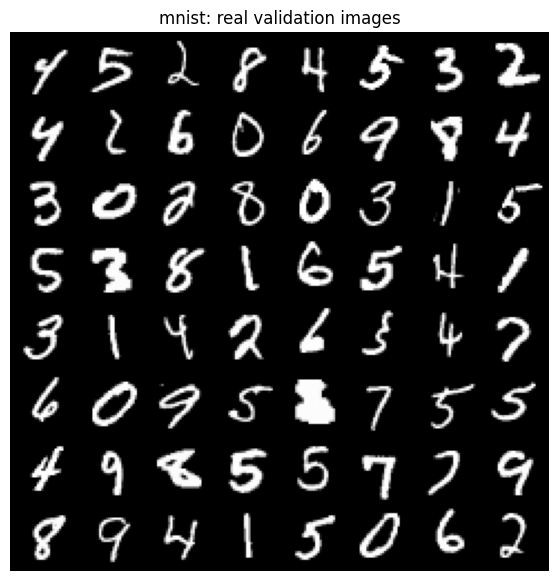

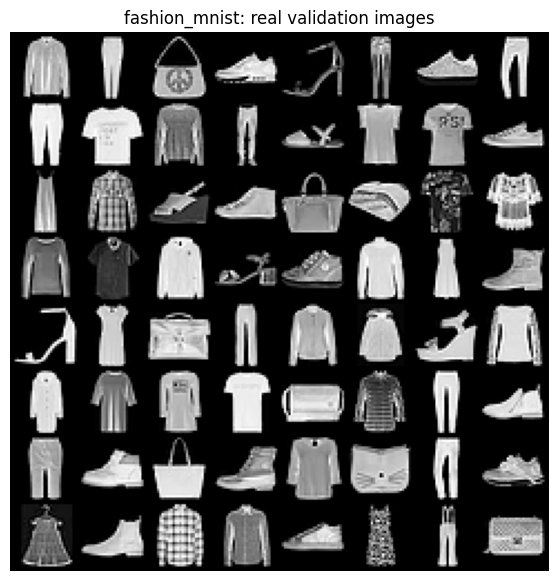

In [2]:
# Native IDX loading avoids any dependency on torchvision compiled operators.
DATASETS = {
    'mnist': 'https://ossci-datasets.s3.amazonaws.com/mnist/',
    'fashion_mnist': 'https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/'
}
def load_idx_dataset(name, train=True):
    folder = DATA_DIR / name / 'raw'
    folder.mkdir(parents=True, exist_ok=True)
    split = 'train' if train else 't10k'
    arrays = []
    for is_image, suffix in [(True, 'images-idx3-ubyte'), (False, 'labels-idx1-ubyte')]:
        filename = f'{split}-{suffix}.gz'
        path = folder / filename
        if not path.exists():
            temporary = path.with_suffix('.download')
            try:
                print('Downloading', name, filename)
                with urllib.request.urlopen(DATASETS[name] + filename, timeout=120) as response:
                    temporary.write_bytes(response.read())
                # Reading through EOF validates the gzip CRC before caching the download.
                with gzip.open(temporary, 'rb') as stream:
                    stream.read()
                temporary.replace(path)
            finally:
                temporary.unlink(missing_ok=True)
        with gzip.open(path, 'rb') as stream:
            magic, count = struct.unpack('>II', stream.read(8))
            if is_image:
                if magic != 2051:
                    raise ValueError('Invalid image IDX header')
                rows, cols = struct.unpack('>II', stream.read(8))
                assert (rows, cols) == (28, 28)
                data = np.frombuffer(stream.read(), dtype=np.uint8).copy().reshape(count, 1, rows, cols)
                arrays.append(torch.from_numpy(data).float() / 255.)
            else:
                if magic != 2049:
                    raise ValueError('Invalid label IDX header')
                data = np.frombuffer(stream.read(), dtype=np.uint8).copy().reshape(count)
                arrays.append(torch.from_numpy(data).long())
    assert len(arrays[0]) == len(arrays[1]) == (60000 if train else 10000)
    return TensorDataset(*arrays)

def make_grid(images, nrow=8, padding=2):
    n, channels, height, width = images.shape
    columns = min(nrow, n)
    rows = math.ceil(n / columns)
    grid = images.new_zeros(channels, rows*(height+padding)+padding,
                           columns*(width+padding)+padding)
    for index, image in enumerate(images):
        row, column = divmod(index, columns)
        top, left = padding+row*(height+padding), padding+column*(width+padding)
        grid[:, top:top+height, left:left+width] = image
    return grid.expand(3, -1, -1) if channels == 1 else grid



load_idx_dataset = lru_cache(maxsize=4)(load_idx_dataset)
def loaders(name):
    full = load_idx_dataset(name,train=True)
    train,val = random_split(full,[50000,10000],generator=torch.Generator().manual_seed(SEED))
    if SMOKE_TEST:
        train,val = Subset(train,range(256)),Subset(val,range(128))
    options=dict(batch_size=BATCH_SIZE,num_workers=0,pin_memory=DEVICE.type=='cuda')
    return (DataLoader(train,shuffle=True,generator=torch.Generator().manual_seed(SEED),**options),
            DataLoader(val,shuffle=False,**options))
def test_loader(name):
    ds=load_idx_dataset(name,train=False)
    if SMOKE_TEST: ds=Subset(ds,range(128))
    return DataLoader(ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=0)
def show(images,title,path,nrow=8):
    fig,ax=plt.subplots(figsize=(7,7))
    ax.imshow(make_grid(images.detach().cpu(),nrow=nrow).permute(1,2,0).numpy(),vmin=0,vmax=1)
    ax.set_title(('SMOKE TEST ONLY | ' if SMOKE_TEST else '')+title)
    ax.axis('off')
    fig.savefig(path,dpi=150,bbox_inches='tight')
    plt.show()
    plt.close(fig)
for name in ACTIVE_DATASETS:
    show(next(iter(loaders(name)[1]))[0][:64],name+': real validation images',REPORT/f'{name}_real.png')

## 2. Architecture: affine coupling and multiple scales

### Affine coupling

A binary mask $m$ keeps some coordinates unchanged. A residual convolutional network reads these coordinates and predicts log-scale $s$ and translation $t$ for the others:

$$z=m\odot x+(1-m)\odot(x\exp(s)+t).$$

The inverse subtracts $t$ and multiplies by $\exp(-s)$. The log-Jacobian is the sum of log-scales over transformed coordinates. Alternating masks allow every coordinate to change. A tanh limits the scales, and a zero-initialized output layer makes each coupling start as the identity. The model has no batch-dependent normalization.

### Multi-scale structure

| Operation | Output / purpose |
|---|---|
| Checkerboard couplings | 1 × 28 × 28; transform alternating pixels |
| Squeeze | 4 × 14 × 14; move pixels into channels |
| Channel couplings | 4 × 14 × 14; transform alternating channel groups |
| Split | Save 2 × 14 × 14 variables as one latent part |
| Squeeze remaining branch | 8 × 7 × 7 |
| Coarse channel couplings | Model relationships at the smaller spatial scale |

Both latent parts have standard normal priors and contain $392+392=784$ values. The split creates the multi-scale model; squeezing alone only rearranges values. Generation samples both parts and reverses all operations.

### Learned channel mixing

An invertible 1×1 matrix $W=\exp(A)$ mixes channels at every spatial location. Its inverse is $\exp(-A)$ and its log-Jacobian is $H W_{\mathrm{spatial}}\,\mathrm{tr}(A)$. Initializing $A$ to zero starts with identity mixing.

Sparse mixing adds one matrix at the end of each channel stage: two in total. Dense mixing adds a matrix after every channel coupling: twelve in total. Unlike a fixed shuffle, these matrices learn combinations of channels.


In [3]:
class Residual(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.net = nn.Sequential(nn.ReLU(), nn.Conv2d(c,c,3,padding=1), nn.ReLU(), nn.Conv2d(c,c,1))
    def forward(self, x):
        return x + self.net(x)

class Coupling(nn.Module):
    def __init__(self, c, h, w, hidden, flip=False, channel=False):
        super().__init__()
        if channel:
            mask = (torch.arange(c) < c//2).float()[None,:,None,None]
        else:
            mask = ((torch.arange(h)[:,None]+torch.arange(w)[None,:])%2).float()[None,None]
        self.register_buffer('mask', 1-mask if flip else mask)
        self.net = nn.Sequential(nn.Conv2d(c,hidden,3,padding=1), nn.ReLU(),
                                 Residual(hidden), Residual(hidden), nn.ReLU(),
                                 nn.Conv2d(hidden,2*c,3,padding=1))
        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)
    def st(self, fixed):
        s,t = self.net(fixed).chunk(2,1)
        return 1.5*torch.tanh(s)*(1-self.mask), t*(1-self.mask)
    def forward(self, x):
        fixed = x*self.mask
        s,t = self.st(fixed)
        return fixed+(1-self.mask)*x*torch.exp(s)+t, s.flatten(1).sum(1)
    def inverse(self, z):
        fixed = z*self.mask
        s,t = self.st(fixed)
        return fixed+(1-self.mask)*(z-t)*torch.exp(-s)

def squeeze(x):
    b,c,h,w = x.shape
    return x.reshape(b,c,h//2,2,w//2,2).permute(0,1,3,5,2,4).reshape(b,4*c,h//2,w//2)
def unsqueeze(x):
    b,c,h,w = x.shape
    return x.reshape(b,c//4,2,2,h,w).permute(0,1,4,2,5,3).reshape(b,c//4,2*h,2*w)

class RealNVP(nn.Module):
    def __init__(self, hidden=32, depth=4, alpha=0.05):
        super().__init__()
        self.alpha = alpha
        self.stages = nn.ModuleList([nn.ModuleList([
            Coupling(c,h,w,hidden,bool(i%2),channel) for i in range(depth)])
            for c,h,w,channel in [(1,28,28,False),(4,14,14,True),(8,7,7,True)]])
    def encode(self, y):
        ldj = y.new_zeros(y.size(0))
        for index,stage in enumerate(self.stages):
            for layer in stage:
                y,delta = layer(y)
                ldj = ldj+delta
            if index == 0:
                y = squeeze(y)
            elif index == 1:
                y,factored = y.chunk(2,1)
                y = squeeze(y)
        return [factored,y], ldj
    def decode(self, parts):
        factored,y = parts
        for index in reversed(range(3)):
            for layer in reversed(self.stages[index]):
                y = layer.inverse(y)
            if index == 2:
                y = torch.cat([unsqueeze(y),factored],1)
            elif index == 1:
                y = unsqueeze(y)
        return y
    def log_prob(self, x, generator=None):
        noise = torch.rand(x.shape, device=x.device, generator=generator)
        u = (255*x+noise)/256
        v = self.alpha+(1-2*self.alpha)*u
        y = torch.log(v)-torch.log1p(-v)
        prep = (math.log(1-2*self.alpha)-torch.log(v)-torch.log1p(-v)).flatten(1).sum(1)
        parts,ldj = self.encode(y)
        prior = sum((-0.5*(z.square()+math.log(2*math.pi))).flatten(1).sum(1) for z in parts)
        return prior+ldj+prep
    @torch.no_grad()
    def sample(self, n=64, temperature=1.0):
        device = next(self.parameters()).device
        g = torch.Generator(device=device).manual_seed(123)
        parts = [torch.randn((n,*shape),device=device,generator=g)*temperature
                 for shape in [(2,14,14),(8,7,7)]]
        u = (torch.sigmoid(self.decode(parts))-self.alpha)/(1-2*self.alpha)
        outside = ((u<0)|(u>1)).float().mean().item()
        return u.clamp(0,1), outside



class InvertibleChannelMix(nn.Module):
    """W=exp(A) is always invertible; log|det W|=trace(A)."""
    def __init__(self, channels):
        super().__init__()
        self.matrix = nn.Parameter(torch.zeros(channels, channels))
    def forward(self, x):
        weight = torch.linalg.matrix_exp(self.matrix)
        y = torch.einsum('ij,bjhw->bihw', weight, x)
        ldj = torch.trace(self.matrix) * x.shape[2] * x.shape[3]
        return y, ldj.expand(x.shape[0])
    def inverse(self, y):
        return torch.einsum('ij,bjhw->bihw', torch.linalg.matrix_exp(-self.matrix), y)


class AblationRealNVP(RealNVP):
    def __init__(self,hidden=64,depth=6,mixing='none'):
        super().__init__(hidden,depth)
        assert mixing in ('none','sparse','dense')
        self.mixing = mixing
        self.mixers=nn.ModuleDict()
        for stage,channels in [(1,4),(2,8)]:
            indices = range(depth) if mixing=='dense' else ([depth-1] if mixing=='sparse' else [])
            for i in indices: self.mixers[f'{stage}_{i}']=InvertibleChannelMix(channels)
    def encode(self,y):
        ldj=y.new_zeros(y.size(0))
        for stage,layers in enumerate(self.stages):
            for i,layer in enumerate(layers):
                y,delta=layer(y)
                ldj=ldj+delta
                key=f'{stage}_{i}'
                if key in self.mixers:
                    y,delta=self.mixers[key](y)
                    ldj=ldj+delta
            if stage==0: y=squeeze(y)
            elif stage==1:
                y,factored=y.chunk(2,1)
                y=squeeze(y)
        return [factored,y],ldj
    def decode(self,parts):
        factored,y=parts
        for stage in reversed(range(3)):
            for i in reversed(range(len(self.stages[stage]))):
                key=f'{stage}_{i}'
                if key in self.mixers: y=self.mixers[key].inverse(y)
                y=self.stages[stage][i].inverse(y)
            if stage==2: y=torch.cat([unsqueeze(y),factored],1)
            elif stage==1: y=unsqueeze(y)
        return y

## 3. Numerical checks

The implementation checks covered both coupling masks, the analytic channel-mixing determinant, squeeze inversion, and full multi-scale inversion with no, sparse and dense mixing. They also checked finite likelihoods and gradients. The saved outputs below contain the check results.


In [4]:
def check_implementation():
    seed_all()
    for mixing in ('none','sparse','dense'):
        model=AblationRealNVP(hidden=8,depth=2,mixing=mixing)
        for layer in model.modules():
            if isinstance(layer,Coupling): nn.init.normal_(layer.net[-1].weight,std=0.005)
            if isinstance(layer,InvertibleChannelMix): nn.init.normal_(layer.matrix,std=0.01)
        x=torch.randn(2,1,28,28)
        torch.testing.assert_close(unsqueeze(squeeze(x)),x)
        parts,_=model.encode(x)
        assert sum(z[0].numel() for z in parts)==784
        torch.testing.assert_close(model.decode(parts),x,atol=3e-5,rtol=3e-5)
        lp=model.log_prob(torch.rand(2,1,28,28))
        assert torch.isfinite(lp).all()
        (-lp.mean()).backward()
        assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in model.parameters())
    for channel,c in [(False,1),(True,2)]:
        layer=Coupling(c,2,2,4,channel=channel).double()
        nn.init.normal_(layer.net[-1].weight,std=0.02)
        x=torch.randn(1,c,2,2,dtype=torch.float64)
        jac=torch.autograd.functional.jacobian(lambda t:layer(t.reshape_as(x))[0].flatten(),x.flatten())
        torch.testing.assert_close(layer(x)[1][0],torch.linalg.slogdet(jac)[1])
    layer=InvertibleChannelMix(2).double()
    nn.init.normal_(layer.matrix,std=0.1)
    x=torch.randn(1,2,2,2,dtype=torch.float64)
    jac=torch.autograd.functional.jacobian(lambda t:layer(t.reshape_as(x))[0].flatten(),x.flatten())
    torch.testing.assert_close(layer(x)[1][0],torch.linalg.slogdet(jac)[1])
    torch.testing.assert_close(layer.inverse(layer(x)[0]),x)
    print('Passed: masked Jacobians, channel-mixing Jacobian, multi-scale inverses, finite gradients.')
check_implementation()


Passed: masked Jacobians, channel-mixing Jacobian, multi-scale inverses, finite gradients.


## 4. Experiments and training

| Experiment | Hidden channels | Couplings per stage | Mixing matrices |
|---|---:|---:|---:|
| Compact baseline | 32 | 4 | 0 |
| Wide baseline | 64 | 6 | 0 |
| Sparse mixing | 64 | 6 | 2 |
| Dense mixing | 64 | 6 | 12 |

Each model was trained from scratch for 40 epochs with Adam at 2e-4, cosine learning-rate decay and gradient clipping at 5. All experiments used the same seed and data split.

The wide models differed only in mixing frequency. The compact-to-wide comparison changed both width and depth, so it measured overall capacity. One seed is not enough to establish statistical significance.

Training and validation NLL/bpd were recorded every epoch. The checkpoint with the lowest validation bpd was selected for each experiment. Fixed-seed samples showed generation changes during training. Better likelihood does not always mean better-looking images.


mnist | compact_baseline | 1/40 | train 4.3535, val 3.0440 bpd | 16.3s


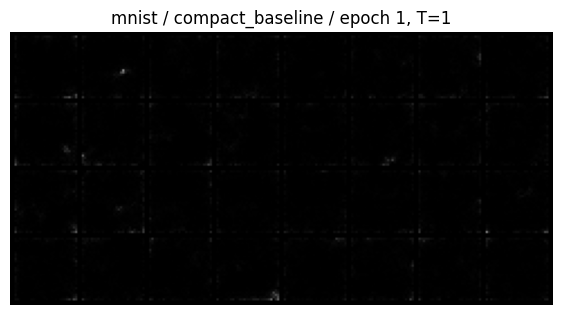

mnist | compact_baseline | 2/40 | train 3.2489, val 2.6283 bpd | 17.0s
mnist | compact_baseline | 3/40 | train 2.6591, val 2.2875 bpd | 16.2s
mnist | compact_baseline | 4/40 | train 2.3655, val 2.2047 bpd | 16.3s
mnist | compact_baseline | 5/40 | train 2.2166, val 2.0458 bpd | 16.8s
mnist | compact_baseline | 6/40 | train 2.0781, val 2.0854 bpd | 16.8s
mnist | compact_baseline | 7/40 | train 1.9823, val 1.9863 bpd | 16.3s
mnist | compact_baseline | 8/40 | train 1.9438, val 1.9230 bpd | 16.7s
mnist | compact_baseline | 9/40 | train 1.8914, val 1.8205 bpd | 16.4s
mnist | compact_baseline | 10/40 | train 1.8521, val 1.7992 bpd | 16.3s


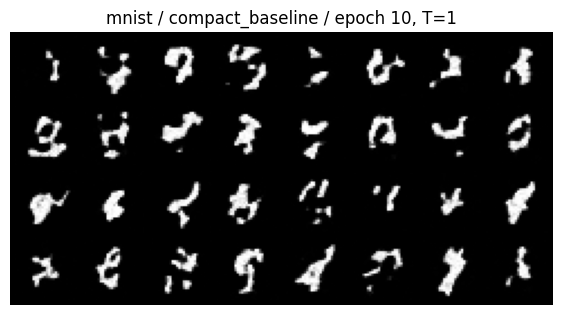

mnist | compact_baseline | 11/40 | train 1.8335, val 1.8538 bpd | 16.5s
mnist | compact_baseline | 12/40 | train 1.7830, val 1.7508 bpd | 16.3s
mnist | compact_baseline | 13/40 | train 1.7532, val 1.8278 bpd | 17.1s
mnist | compact_baseline | 14/40 | train 1.7284, val 1.7064 bpd | 16.6s
mnist | compact_baseline | 15/40 | train 1.7133, val 1.6755 bpd | 16.8s
mnist | compact_baseline | 16/40 | train 1.6987, val 1.6553 bpd | 17.1s
mnist | compact_baseline | 17/40 | train 1.6867, val 1.6471 bpd | 16.9s
mnist | compact_baseline | 18/40 | train 1.6585, val 1.6431 bpd | 16.9s
mnist | compact_baseline | 19/40 | train 1.6619, val 1.6242 bpd | 17.3s
mnist | compact_baseline | 20/40 | train 1.6446, val 1.6131 bpd | 16.6s


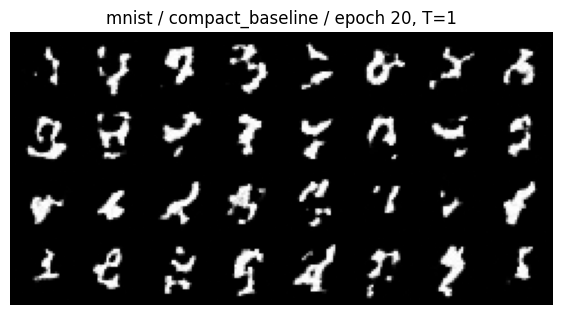

mnist | compact_baseline | 21/40 | train 1.6446, val 1.6529 bpd | 16.5s
mnist | compact_baseline | 22/40 | train 1.6154, val 1.6171 bpd | 16.4s
mnist | compact_baseline | 23/40 | train 1.6036, val 1.6651 bpd | 16.1s
mnist | compact_baseline | 24/40 | train 1.5973, val 1.5761 bpd | 16.1s
mnist | compact_baseline | 25/40 | train 1.5996, val 1.6172 bpd | 16.3s
mnist | compact_baseline | 26/40 | train 1.5854, val 1.5757 bpd | 16.1s
mnist | compact_baseline | 27/40 | train 1.5733, val 1.5651 bpd | 16.6s
mnist | compact_baseline | 28/40 | train 1.5653, val 1.5531 bpd | 16.6s
mnist | compact_baseline | 29/40 | train 1.5547, val 1.5497 bpd | 16.3s
mnist | compact_baseline | 30/40 | train 1.5564, val 1.5544 bpd | 16.3s


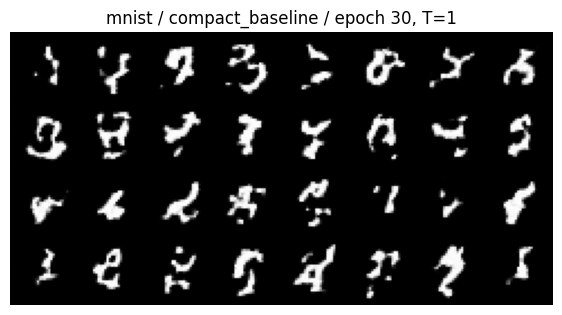

mnist | compact_baseline | 31/40 | train 1.5495, val 1.5407 bpd | 16.4s
mnist | compact_baseline | 32/40 | train 1.5458, val 1.5441 bpd | 16.3s
mnist | compact_baseline | 33/40 | train 1.5409, val 1.5361 bpd | 15.9s
mnist | compact_baseline | 34/40 | train 1.5385, val 1.5331 bpd | 16.4s
mnist | compact_baseline | 35/40 | train 1.5356, val 1.5308 bpd | 16.4s
mnist | compact_baseline | 36/40 | train 1.5335, val 1.5302 bpd | 16.2s
mnist | compact_baseline | 37/40 | train 1.5317, val 1.5299 bpd | 16.2s
mnist | compact_baseline | 38/40 | train 1.5306, val 1.5276 bpd | 16.3s
mnist | compact_baseline | 39/40 | train 1.5298, val 1.5272 bpd | 16.4s
mnist | compact_baseline | 40/40 | train 1.5293, val 1.5266 bpd | 16.3s


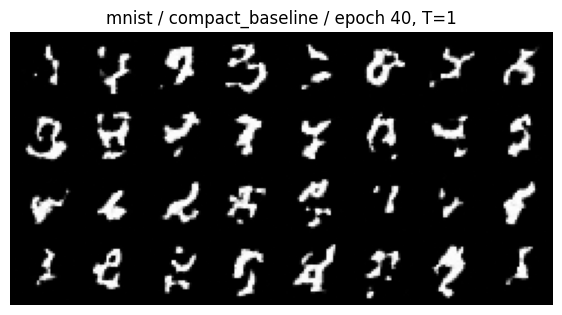

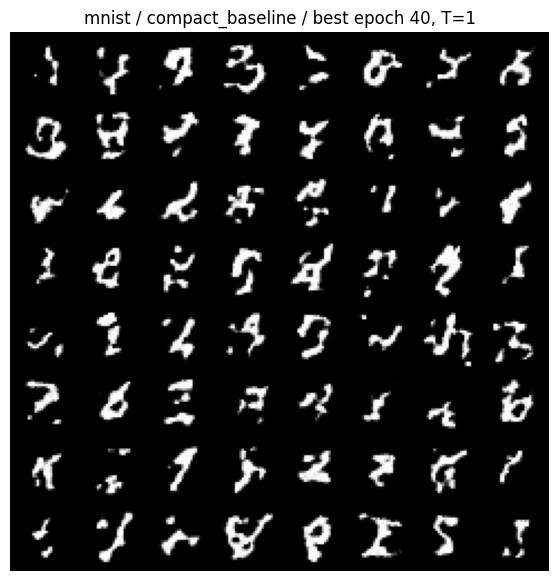

mnist | wide_baseline | 1/40 | train 4.4995, val 3.1277 bpd | 38.7s


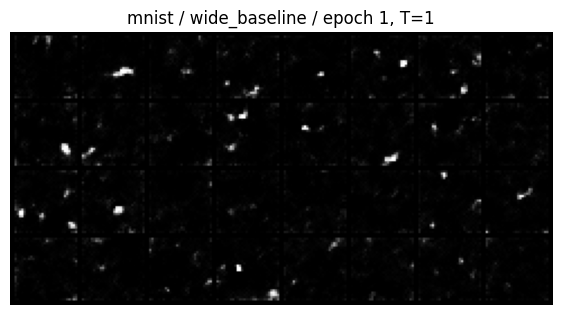

mnist | wide_baseline | 2/40 | train 2.8671, val 2.6208 bpd | 38.7s
mnist | wide_baseline | 3/40 | train 2.3610, val 2.0735 bpd | 38.6s
mnist | wide_baseline | 4/40 | train 2.0381, val 1.8436 bpd | 39.0s
mnist | wide_baseline | 5/40 | train 1.9783, val 1.8116 bpd | 38.8s
mnist | wide_baseline | 6/40 | train 1.8300, val 1.8181 bpd | 38.8s
mnist | wide_baseline | 7/40 | train 1.7440, val 1.7566 bpd | 38.6s
mnist | wide_baseline | 8/40 | train 1.7073, val 1.6981 bpd | 38.7s
mnist | wide_baseline | 9/40 | train 1.6871, val 1.6201 bpd | 38.9s
mnist | wide_baseline | 10/40 | train 1.6311, val 1.6774 bpd | 38.7s


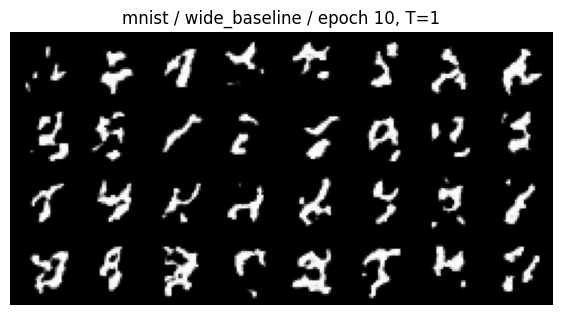

mnist | wide_baseline | 11/40 | train 1.5942, val 1.5409 bpd | 38.8s
mnist | wide_baseline | 12/40 | train 1.5816, val 1.5386 bpd | 38.9s
mnist | wide_baseline | 13/40 | train 1.5405, val 1.5379 bpd | 39.0s
mnist | wide_baseline | 14/40 | train 1.5127, val 1.5634 bpd | 39.0s
mnist | wide_baseline | 15/40 | train 1.5178, val 1.4764 bpd | 38.9s
mnist | wide_baseline | 16/40 | train 1.4942, val 1.4520 bpd | 38.8s
mnist | wide_baseline | 17/40 | train 1.4718, val 1.4730 bpd | 38.7s
mnist | wide_baseline | 18/40 | train 1.4727, val 1.4518 bpd | 39.0s
mnist | wide_baseline | 19/40 | train 1.4741, val 1.4244 bpd | 38.8s
mnist | wide_baseline | 20/40 | train 1.4436, val 1.4508 bpd | 38.8s


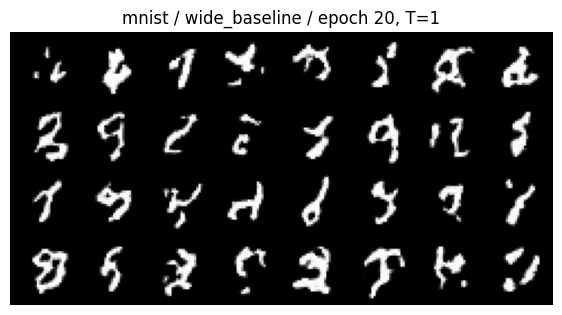

mnist | wide_baseline | 21/40 | train 1.4208, val 1.4007 bpd | 38.9s
mnist | wide_baseline | 22/40 | train 1.4225, val 1.3956 bpd | 38.8s
mnist | wide_baseline | 23/40 | train 1.4027, val 1.3863 bpd | 39.2s
mnist | wide_baseline | 24/40 | train 1.3972, val 1.3849 bpd | 38.9s
mnist | wide_baseline | 25/40 | train 1.3918, val 1.3818 bpd | 38.7s
mnist | wide_baseline | 26/40 | train 1.3832, val 1.3780 bpd | 38.8s
mnist | wide_baseline | 27/40 | train 1.3708, val 1.3685 bpd | 38.9s
mnist | wide_baseline | 28/40 | train 1.3724, val 1.3598 bpd | 39.0s
mnist | wide_baseline | 29/40 | train 1.3598, val 1.3503 bpd | 39.0s
mnist | wide_baseline | 30/40 | train 1.3543, val 1.3470 bpd | 38.7s


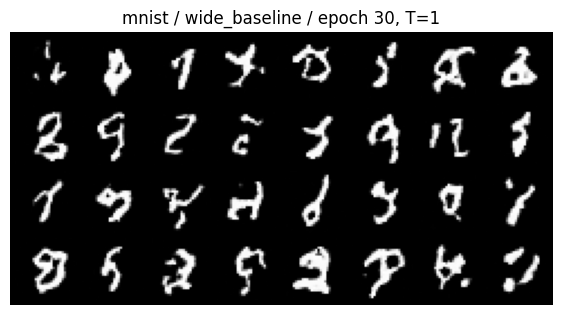

mnist | wide_baseline | 31/40 | train 1.3501, val 1.3845 bpd | 38.8s
mnist | wide_baseline | 32/40 | train 1.3457, val 1.3470 bpd | 39.0s
mnist | wide_baseline | 33/40 | train 1.3444, val 1.3518 bpd | 38.7s
mnist | wide_baseline | 34/40 | train 1.3377, val 1.3316 bpd | 38.7s
mnist | wide_baseline | 35/40 | train 1.3347, val 1.3294 bpd | 38.7s
mnist | wide_baseline | 36/40 | train 1.3311, val 1.3289 bpd | 38.8s
mnist | wide_baseline | 37/40 | train 1.3285, val 1.3267 bpd | 38.8s
mnist | wide_baseline | 38/40 | train 1.3267, val 1.3243 bpd | 38.8s
mnist | wide_baseline | 39/40 | train 1.3254, val 1.3236 bpd | 38.6s
mnist | wide_baseline | 40/40 | train 1.3247, val 1.3229 bpd | 38.7s


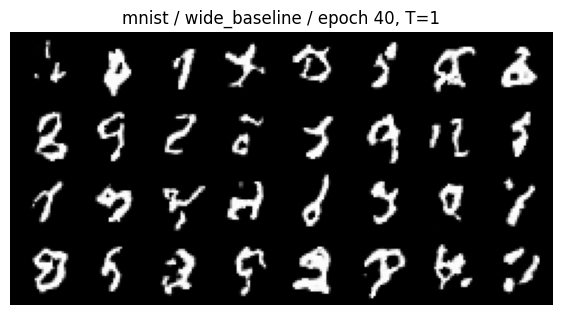

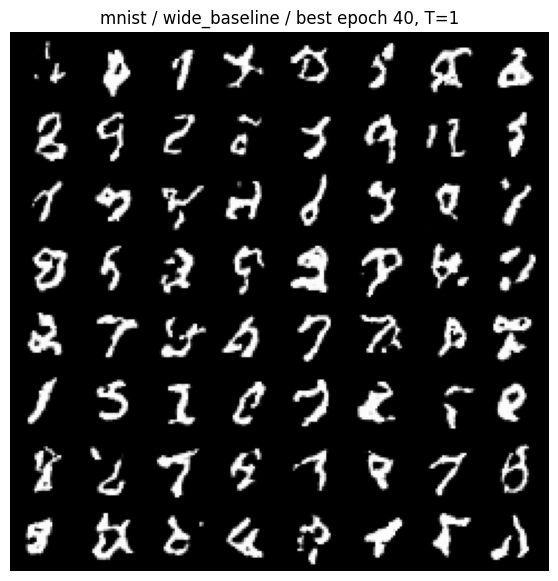

mnist | sparse_mixing | 1/40 | train 4.2459, val 2.8020 bpd | 43.7s


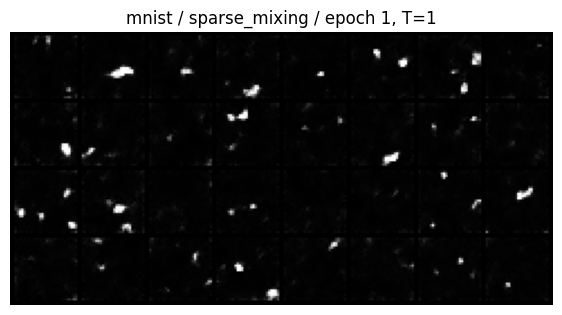

mnist | sparse_mixing | 2/40 | train 2.7024, val 2.1112 bpd | 43.4s
mnist | sparse_mixing | 3/40 | train 2.2293, val 2.1723 bpd | 43.6s
mnist | sparse_mixing | 4/40 | train 2.0577, val 1.8647 bpd | 142.1s
mnist | sparse_mixing | 5/40 | train 1.9432, val 2.0381 bpd | 32.4s
mnist | sparse_mixing | 6/40 | train 1.8396, val 1.6922 bpd | 31.7s
mnist | sparse_mixing | 7/40 | train 1.7784, val 1.7248 bpd | 31.9s
mnist | sparse_mixing | 8/40 | train 1.7060, val 1.6614 bpd | 32.7s
mnist | sparse_mixing | 9/40 | train 1.6507, val 1.7246 bpd | 32.3s
mnist | sparse_mixing | 10/40 | train 1.6217, val 1.7918 bpd | 32.2s


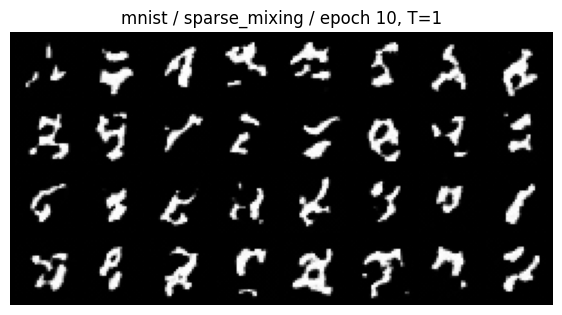

mnist | sparse_mixing | 11/40 | train 1.6053, val 1.5427 bpd | 32.1s
mnist | sparse_mixing | 12/40 | train 1.5699, val 1.5474 bpd | 32.1s
mnist | sparse_mixing | 13/40 | train 1.5394, val 1.4988 bpd | 32.3s
mnist | sparse_mixing | 14/40 | train 1.5304, val 1.6082 bpd | 32.3s
mnist | sparse_mixing | 15/40 | train 1.5171, val 1.6098 bpd | 32.3s
mnist | sparse_mixing | 16/40 | train 1.4907, val 1.4488 bpd | 32.2s
mnist | sparse_mixing | 17/40 | train 1.4790, val 1.5584 bpd | 32.2s
mnist | sparse_mixing | 18/40 | train 1.4666, val 1.5502 bpd | 32.2s
mnist | sparse_mixing | 19/40 | train 1.4637, val 1.4535 bpd | 32.4s
mnist | sparse_mixing | 20/40 | train 1.4351, val 1.4118 bpd | 32.3s


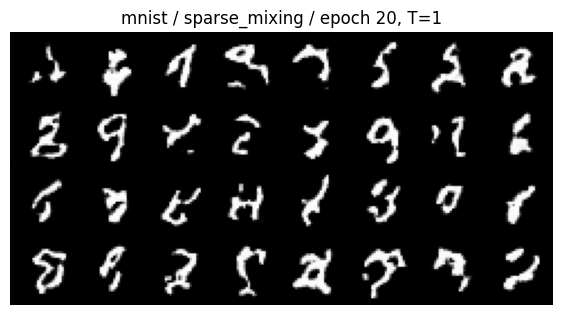

mnist | sparse_mixing | 21/40 | train 1.4219, val 1.4848 bpd | 32.4s
mnist | sparse_mixing | 22/40 | train 1.4211, val 1.4066 bpd | 32.0s
mnist | sparse_mixing | 23/40 | train 1.4120, val 1.3889 bpd | 32.1s
mnist | sparse_mixing | 24/40 | train 1.4060, val 1.3879 bpd | 32.1s
mnist | sparse_mixing | 25/40 | train 1.3984, val 1.3839 bpd | 32.5s
mnist | sparse_mixing | 26/40 | train 1.3849, val 1.3739 bpd | 32.1s
mnist | sparse_mixing | 27/40 | train 1.3754, val 1.3707 bpd | 32.3s
mnist | sparse_mixing | 28/40 | train 1.3814, val 1.3734 bpd | 32.1s
mnist | sparse_mixing | 29/40 | train 1.3693, val 1.3596 bpd | 32.2s
mnist | sparse_mixing | 30/40 | train 1.3628, val 1.3570 bpd | 32.4s


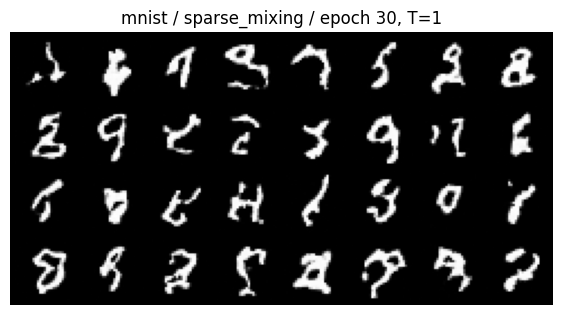

mnist | sparse_mixing | 31/40 | train 1.3619, val 1.3607 bpd | 32.3s
mnist | sparse_mixing | 32/40 | train 1.3577, val 1.3579 bpd | 32.0s
mnist | sparse_mixing | 33/40 | train 1.3521, val 1.3496 bpd | 32.1s
mnist | sparse_mixing | 34/40 | train 1.3483, val 1.3431 bpd | 32.1s
mnist | sparse_mixing | 35/40 | train 1.3460, val 1.3485 bpd | 32.1s
mnist | sparse_mixing | 36/40 | train 1.3431, val 1.3399 bpd | 32.4s
mnist | sparse_mixing | 37/40 | train 1.3409, val 1.3392 bpd | 32.0s
mnist | sparse_mixing | 38/40 | train 1.3394, val 1.3373 bpd | 32.2s
mnist | sparse_mixing | 39/40 | train 1.3383, val 1.3365 bpd | 31.9s
mnist | sparse_mixing | 40/40 | train 1.3377, val 1.3359 bpd | 32.2s


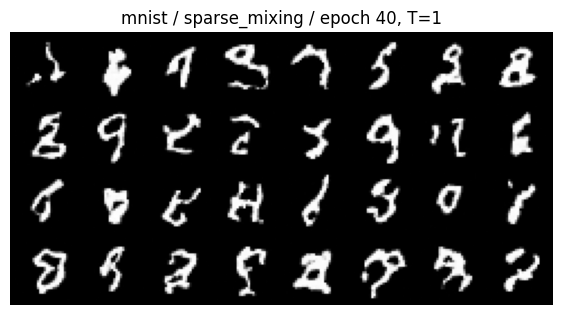

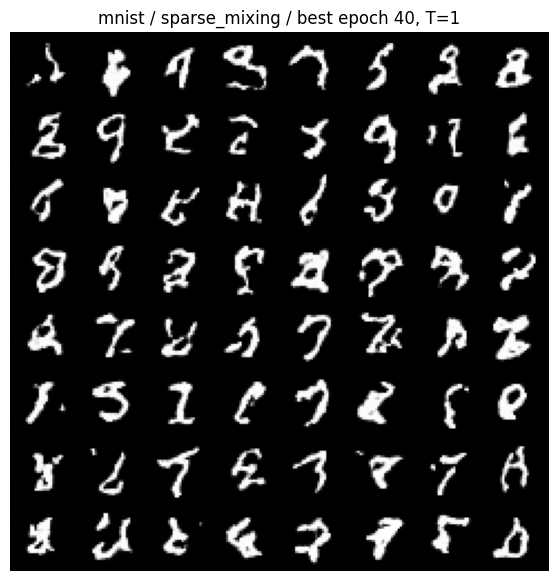

mnist | dense_mixing | 1/40 | train 4.1711, val 2.8400 bpd | 44.1s


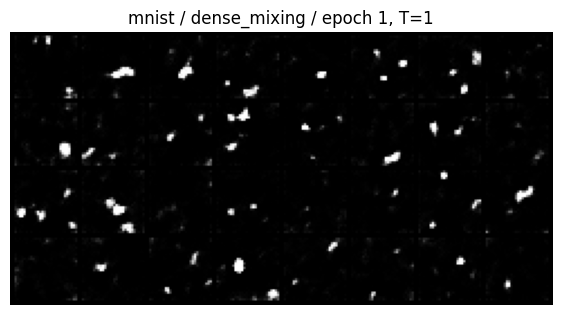

mnist | dense_mixing | 2/40 | train 2.6074, val 2.1465 bpd | 43.4s
mnist | dense_mixing | 3/40 | train 2.1130, val 1.8820 bpd | 43.3s
mnist | dense_mixing | 4/40 | train 1.9525, val 1.9546 bpd | 43.0s
mnist | dense_mixing | 5/40 | train 1.8585, val 1.8850 bpd | 43.6s
mnist | dense_mixing | 6/40 | train 1.7697, val 1.7575 bpd | 43.2s
mnist | dense_mixing | 7/40 | train 1.7324, val 1.7137 bpd | 43.2s
mnist | dense_mixing | 8/40 | train 1.6845, val 1.6503 bpd | 43.3s
mnist | dense_mixing | 9/40 | train 1.6708, val 1.5757 bpd | 43.4s
mnist | dense_mixing | 10/40 | train 1.6104, val 1.6074 bpd | 43.6s


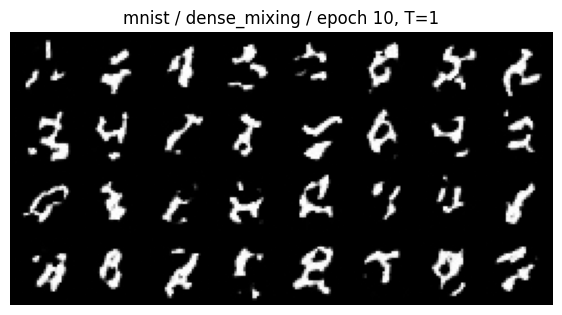

mnist | dense_mixing | 11/40 | train 1.5925, val 1.6105 bpd | 43.5s
mnist | dense_mixing | 12/40 | train 1.5679, val 1.5346 bpd | 42.6s
mnist | dense_mixing | 13/40 | train 1.5619, val 1.5275 bpd | 43.0s
mnist | dense_mixing | 14/40 | train 1.5150, val 1.5705 bpd | 43.5s
mnist | dense_mixing | 15/40 | train 1.4946, val 1.4414 bpd | 43.6s
mnist | dense_mixing | 16/40 | train 1.4856, val 1.5055 bpd | 44.7s
mnist | dense_mixing | 17/40 | train 1.4655, val 1.4320 bpd | 44.1s
mnist | dense_mixing | 18/40 | train 1.4495, val 1.4620 bpd | 44.2s
mnist | dense_mixing | 19/40 | train 1.4417, val 1.4373 bpd | 43.5s
mnist | dense_mixing | 20/40 | train 1.4315, val 1.4027 bpd | 42.6s


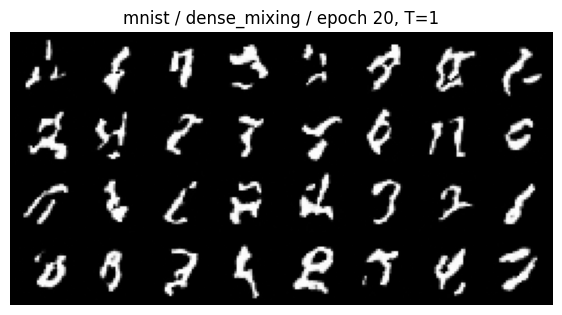

mnist | dense_mixing | 21/40 | train 1.4209, val 1.4146 bpd | 43.0s
mnist | dense_mixing | 22/40 | train 1.4060, val 1.3934 bpd | 43.8s
mnist | dense_mixing | 23/40 | train 1.3952, val 1.3737 bpd | 43.0s
mnist | dense_mixing | 24/40 | train 1.3882, val 1.3890 bpd | 43.2s
mnist | dense_mixing | 25/40 | train 1.3857, val 1.3938 bpd | 43.4s
mnist | dense_mixing | 26/40 | train 1.3740, val 1.3588 bpd | 43.6s
mnist | dense_mixing | 27/40 | train 1.3630, val 1.3511 bpd | 43.4s
mnist | dense_mixing | 28/40 | train 1.3622, val 1.3578 bpd | 43.3s
mnist | dense_mixing | 29/40 | train 1.3563, val 1.3455 bpd | 42.8s
mnist | dense_mixing | 30/40 | train 1.3473, val 1.3373 bpd | 43.3s


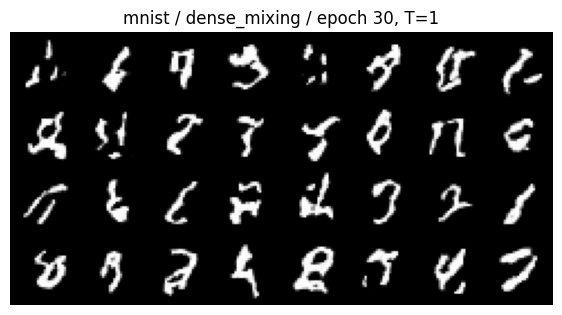

mnist | dense_mixing | 31/40 | train 1.3395, val 1.3330 bpd | 43.3s
mnist | dense_mixing | 32/40 | train 1.3381, val 1.3421 bpd | 43.5s
mnist | dense_mixing | 33/40 | train 1.3331, val 1.3292 bpd | 43.3s
mnist | dense_mixing | 34/40 | train 1.3311, val 1.3299 bpd | 44.2s
mnist | dense_mixing | 35/40 | train 1.3262, val 1.3223 bpd | 44.7s
mnist | dense_mixing | 36/40 | train 1.3228, val 1.3198 bpd | 43.5s
mnist | dense_mixing | 37/40 | train 1.3207, val 1.3187 bpd | 43.2s
mnist | dense_mixing | 38/40 | train 1.3193, val 1.3175 bpd | 43.5s
mnist | dense_mixing | 39/40 | train 1.3178, val 1.3159 bpd | 43.5s
mnist | dense_mixing | 40/40 | train 1.3173, val 1.3154 bpd | 44.2s


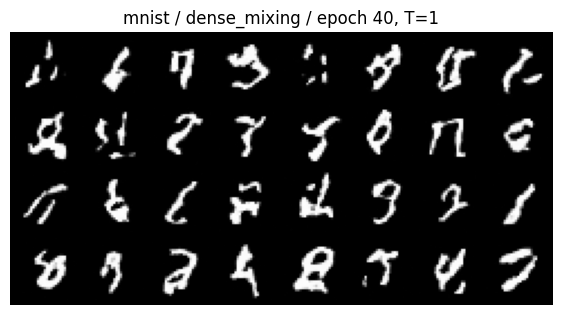

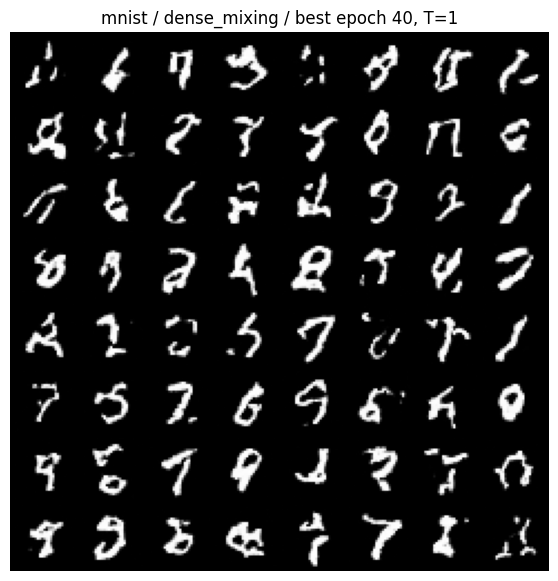

fashion_mnist | compact_baseline | 1/40 | train 5.6724, val 5.2189 bpd | 13.1s


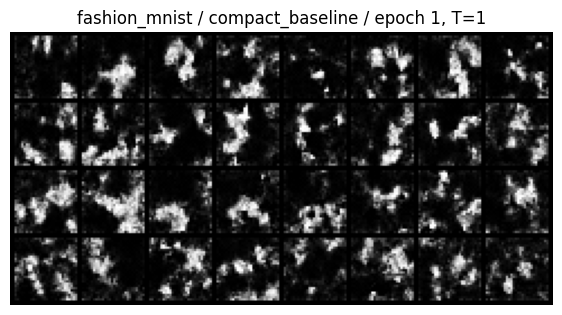

fashion_mnist | compact_baseline | 2/40 | train 4.8570, val 4.5514 bpd | 13.1s
fashion_mnist | compact_baseline | 3/40 | train 4.4628, val 4.2672 bpd | 12.9s
fashion_mnist | compact_baseline | 4/40 | train 4.3214, val 4.1638 bpd | 13.0s
fashion_mnist | compact_baseline | 5/40 | train 4.1289, val 4.1291 bpd | 12.9s
fashion_mnist | compact_baseline | 6/40 | train 4.0516, val 3.9464 bpd | 13.0s
fashion_mnist | compact_baseline | 7/40 | train 3.9432, val 3.9045 bpd | 13.2s
fashion_mnist | compact_baseline | 8/40 | train 3.8730, val 3.8221 bpd | 13.3s
fashion_mnist | compact_baseline | 9/40 | train 3.8399, val 3.8362 bpd | 13.0s
fashion_mnist | compact_baseline | 10/40 | train 3.7888, val 3.7365 bpd | 13.2s


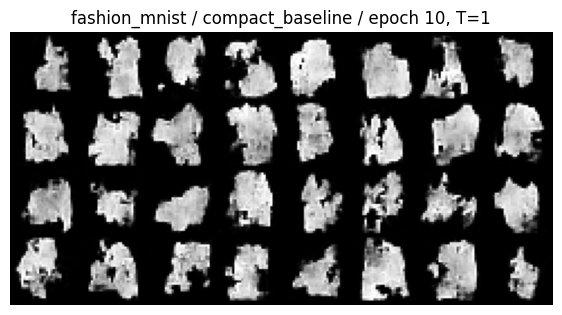

fashion_mnist | compact_baseline | 11/40 | train 3.7338, val 3.8999 bpd | 13.1s
fashion_mnist | compact_baseline | 12/40 | train 3.7070, val 3.7154 bpd | 13.5s
fashion_mnist | compact_baseline | 13/40 | train 3.6727, val 3.8069 bpd | 13.3s
fashion_mnist | compact_baseline | 14/40 | train 3.6329, val 3.6056 bpd | 12.9s
fashion_mnist | compact_baseline | 15/40 | train 3.6157, val 3.5899 bpd | 13.0s
fashion_mnist | compact_baseline | 16/40 | train 3.5901, val 3.5666 bpd | 13.0s
fashion_mnist | compact_baseline | 17/40 | train 3.5680, val 3.5676 bpd | 12.9s
fashion_mnist | compact_baseline | 18/40 | train 3.5561, val 3.5471 bpd | 13.0s
fashion_mnist | compact_baseline | 19/40 | train 3.5347, val 3.5383 bpd | 13.6s
fashion_mnist | compact_baseline | 20/40 | train 3.5331, val 3.5260 bpd | 13.5s


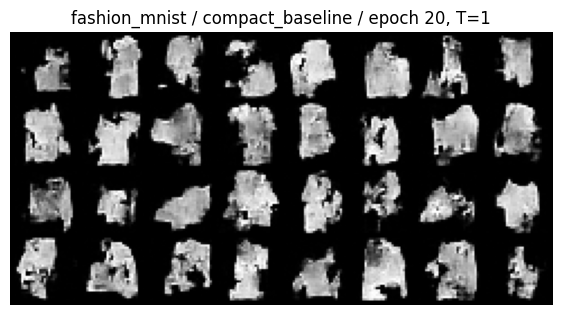

fashion_mnist | compact_baseline | 21/40 | train 3.5136, val 3.5349 bpd | 13.2s
fashion_mnist | compact_baseline | 22/40 | train 3.5072, val 3.5058 bpd | 12.9s
fashion_mnist | compact_baseline | 23/40 | train 3.5025, val 3.5268 bpd | 12.9s
fashion_mnist | compact_baseline | 24/40 | train 3.4773, val 3.4831 bpd | 13.0s
fashion_mnist | compact_baseline | 25/40 | train 3.4824, val 3.4877 bpd | 13.1s
fashion_mnist | compact_baseline | 26/40 | train 3.4659, val 3.4677 bpd | 13.1s
fashion_mnist | compact_baseline | 27/40 | train 3.4472, val 3.4647 bpd | 13.3s
fashion_mnist | compact_baseline | 28/40 | train 3.4489, val 3.4560 bpd | 13.1s
fashion_mnist | compact_baseline | 29/40 | train 3.4388, val 3.4680 bpd | 13.6s
fashion_mnist | compact_baseline | 30/40 | train 3.4346, val 3.4513 bpd | 13.1s


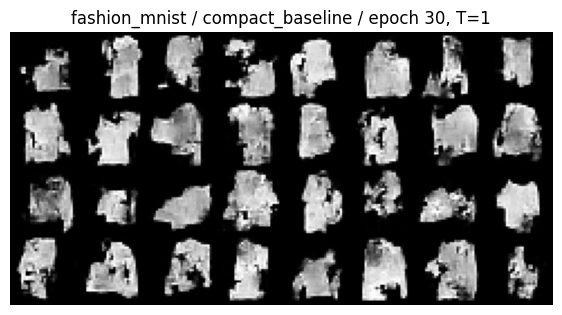

fashion_mnist | compact_baseline | 31/40 | train 3.4282, val 3.4571 bpd | 13.7s
fashion_mnist | compact_baseline | 32/40 | train 3.4242, val 3.4402 bpd | 13.0s
fashion_mnist | compact_baseline | 33/40 | train 3.4187, val 3.4445 bpd | 13.3s
fashion_mnist | compact_baseline | 34/40 | train 3.4151, val 3.4358 bpd | 13.3s
fashion_mnist | compact_baseline | 35/40 | train 3.4120, val 3.4335 bpd | 13.3s
fashion_mnist | compact_baseline | 36/40 | train 3.4099, val 3.4339 bpd | 13.1s
fashion_mnist | compact_baseline | 37/40 | train 3.4080, val 3.4340 bpd | 13.1s
fashion_mnist | compact_baseline | 38/40 | train 3.4067, val 3.4358 bpd | 13.1s
fashion_mnist | compact_baseline | 39/40 | train 3.4058, val 3.4353 bpd | 13.3s
fashion_mnist | compact_baseline | 40/40 | train 3.4052, val 3.4350 bpd | 13.3s


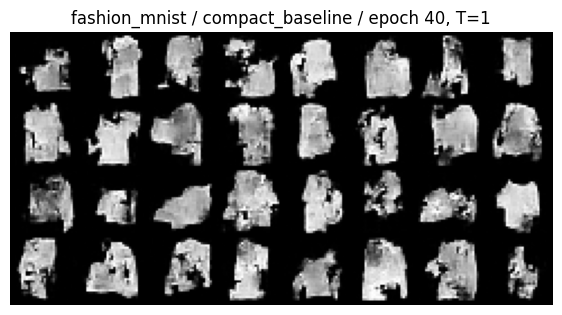

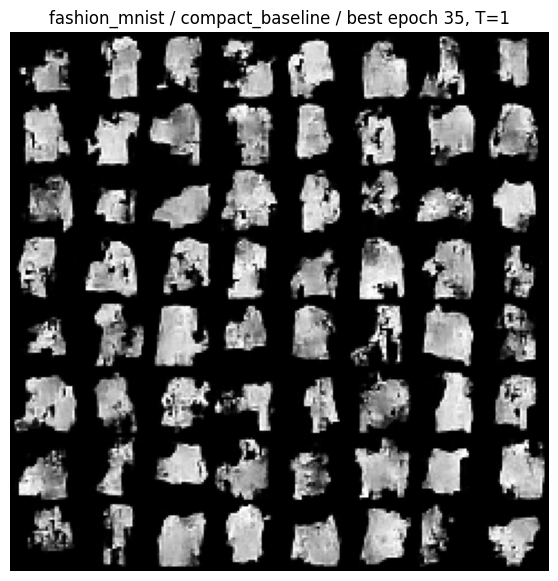

fashion_mnist | wide_baseline | 1/40 | train 6.2497, val 4.6242 bpd | 28.6s


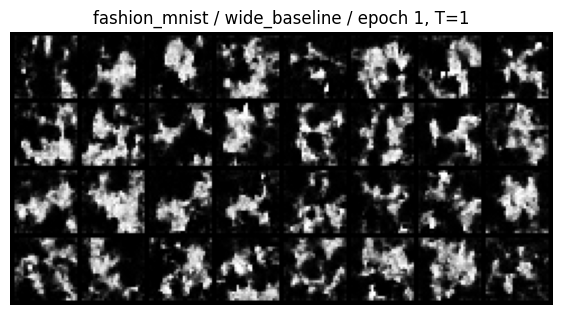

fashion_mnist | wide_baseline | 2/40 | train 4.4227, val 4.2239 bpd | 28.7s
fashion_mnist | wide_baseline | 3/40 | train 4.0828, val 3.9301 bpd | 28.8s
fashion_mnist | wide_baseline | 4/40 | train 3.8797, val 3.7428 bpd | 28.6s
fashion_mnist | wide_baseline | 5/40 | train 3.7457, val 3.6192 bpd | 28.8s
fashion_mnist | wide_baseline | 6/40 | train 3.6453, val 3.5758 bpd | 28.8s
fashion_mnist | wide_baseline | 7/40 | train 3.5609, val 3.4643 bpd | 28.7s
fashion_mnist | wide_baseline | 8/40 | train 3.5191, val 3.5508 bpd | 28.8s
fashion_mnist | wide_baseline | 9/40 | train 3.4717, val 3.4426 bpd | 28.6s
fashion_mnist | wide_baseline | 10/40 | train 3.4442, val 3.4189 bpd | 28.9s


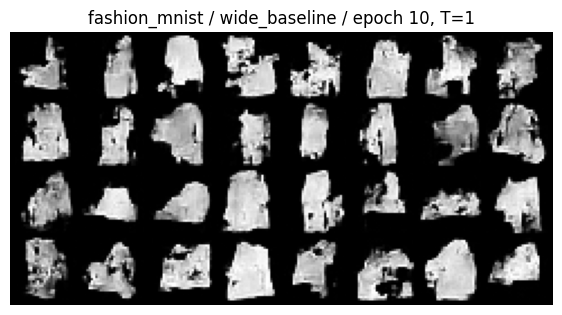

fashion_mnist | wide_baseline | 11/40 | train 3.4320, val 3.4825 bpd | 29.0s
fashion_mnist | wide_baseline | 12/40 | train 3.4076, val 3.5149 bpd | 28.6s
fashion_mnist | wide_baseline | 13/40 | train 3.3874, val 3.4133 bpd | 28.7s
fashion_mnist | wide_baseline | 14/40 | train 3.3436, val 3.3220 bpd | 28.5s
fashion_mnist | wide_baseline | 15/40 | train 3.3439, val 3.3071 bpd | 28.6s
fashion_mnist | wide_baseline | 16/40 | train 3.2972, val 3.3013 bpd | 28.8s
fashion_mnist | wide_baseline | 17/40 | train 3.2889, val 3.2751 bpd | 28.7s
fashion_mnist | wide_baseline | 18/40 | train 3.2975, val 3.4055 bpd | 28.7s
fashion_mnist | wide_baseline | 19/40 | train 3.2726, val 3.3200 bpd | 28.7s
fashion_mnist | wide_baseline | 20/40 | train 3.2724, val 3.2602 bpd | 28.6s


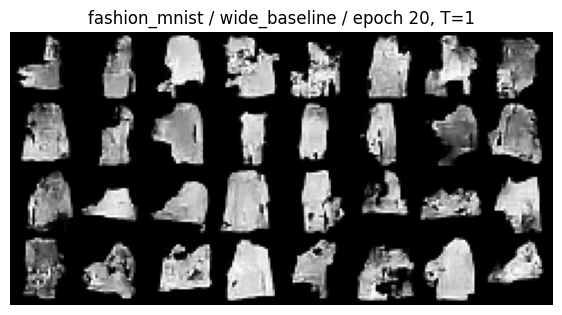

fashion_mnist | wide_baseline | 21/40 | train 3.2428, val 3.2478 bpd | 28.8s
fashion_mnist | wide_baseline | 22/40 | train 3.2363, val 3.2357 bpd | 28.8s
fashion_mnist | wide_baseline | 23/40 | train 3.2237, val 3.2378 bpd | 29.0s
fashion_mnist | wide_baseline | 24/40 | train 3.2114, val 3.2232 bpd | 28.6s
fashion_mnist | wide_baseline | 25/40 | train 3.2145, val 3.2153 bpd | 28.7s
fashion_mnist | wide_baseline | 26/40 | train 3.2023, val 3.2182 bpd | 28.6s
fashion_mnist | wide_baseline | 27/40 | train 3.1928, val 3.1986 bpd | 28.7s
fashion_mnist | wide_baseline | 28/40 | train 3.1935, val 3.2212 bpd | 28.6s
fashion_mnist | wide_baseline | 29/40 | train 3.1831, val 3.1977 bpd | 28.8s
fashion_mnist | wide_baseline | 30/40 | train 3.1841, val 3.1901 bpd | 28.8s


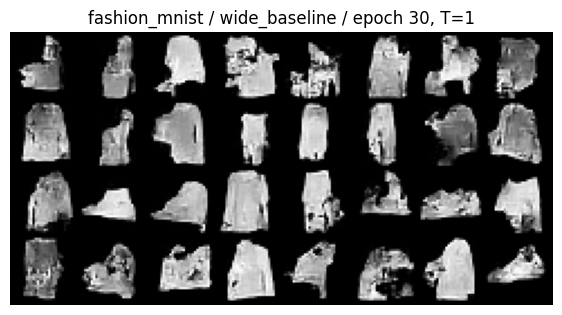

fashion_mnist | wide_baseline | 31/40 | train 3.1695, val 3.1857 bpd | 28.7s
fashion_mnist | wide_baseline | 32/40 | train 3.1684, val 3.1807 bpd | 28.8s
fashion_mnist | wide_baseline | 33/40 | train 3.1640, val 3.1795 bpd | 28.6s
fashion_mnist | wide_baseline | 34/40 | train 3.1602, val 3.1760 bpd | 28.8s
fashion_mnist | wide_baseline | 35/40 | train 3.1578, val 3.1760 bpd | 29.0s
fashion_mnist | wide_baseline | 36/40 | train 3.1554, val 3.1750 bpd | 29.0s
fashion_mnist | wide_baseline | 37/40 | train 3.1535, val 3.1721 bpd | 28.6s
fashion_mnist | wide_baseline | 38/40 | train 3.1522, val 3.1714 bpd | 28.8s
fashion_mnist | wide_baseline | 39/40 | train 3.1514, val 3.1705 bpd | 28.6s
fashion_mnist | wide_baseline | 40/40 | train 3.1508, val 3.1702 bpd | 28.6s


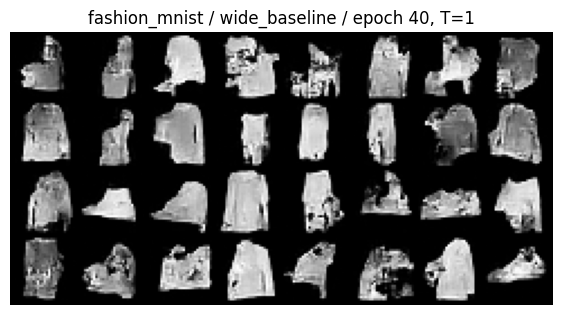

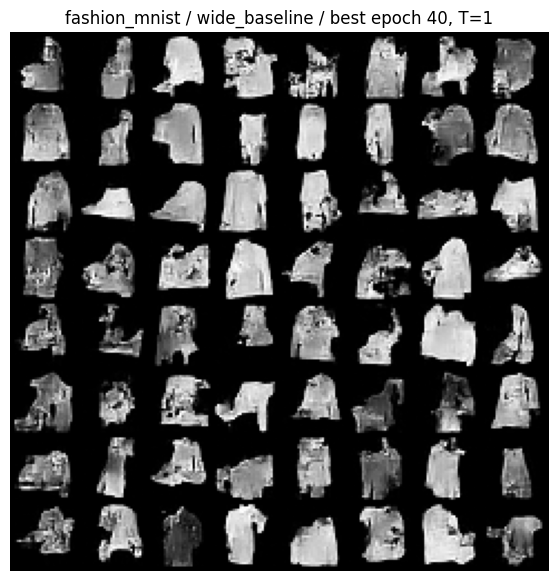

fashion_mnist | sparse_mixing | 1/40 | train 5.1399, val 4.4728 bpd | 32.6s


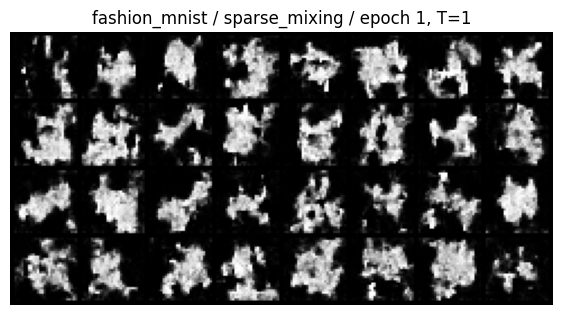

fashion_mnist | sparse_mixing | 2/40 | train 4.3842, val 4.1183 bpd | 32.4s
fashion_mnist | sparse_mixing | 3/40 | train 4.1010, val 3.9603 bpd | 32.3s
fashion_mnist | sparse_mixing | 4/40 | train 3.9650, val 3.7199 bpd | 32.3s
fashion_mnist | sparse_mixing | 5/40 | train 3.7679, val 3.6782 bpd | 32.0s
fashion_mnist | sparse_mixing | 6/40 | train 3.6429, val 3.5768 bpd | 32.3s
fashion_mnist | sparse_mixing | 7/40 | train 3.5784, val 3.5902 bpd | 33.3s
fashion_mnist | sparse_mixing | 8/40 | train 3.5224, val 3.4867 bpd | 32.8s
fashion_mnist | sparse_mixing | 9/40 | train 3.4733, val 3.4125 bpd | 32.4s
fashion_mnist | sparse_mixing | 10/40 | train 3.4348, val 3.5212 bpd | 31.9s


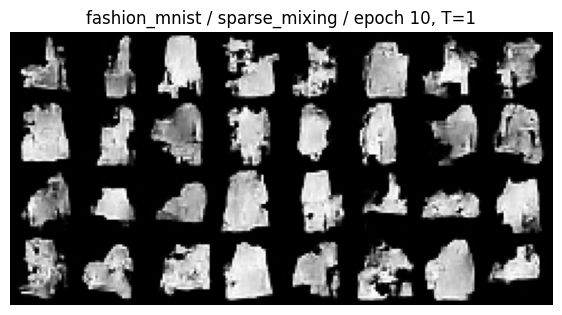

fashion_mnist | sparse_mixing | 11/40 | train 3.4112, val 3.4317 bpd | 32.1s
fashion_mnist | sparse_mixing | 12/40 | train 3.3916, val 3.3896 bpd | 33.1s
fashion_mnist | sparse_mixing | 13/40 | train 3.3609, val 3.3362 bpd | 32.9s
fashion_mnist | sparse_mixing | 14/40 | train 3.3595, val 3.4095 bpd | 32.6s
fashion_mnist | sparse_mixing | 15/40 | train 3.3401, val 3.3074 bpd | 32.1s
fashion_mnist | sparse_mixing | 16/40 | train 3.3051, val 3.2891 bpd | 32.0s
fashion_mnist | sparse_mixing | 17/40 | train 3.2995, val 3.3065 bpd | 32.7s
fashion_mnist | sparse_mixing | 18/40 | train 3.3030, val 3.2672 bpd | 190.4s
fashion_mnist | sparse_mixing | 19/40 | train 3.2845, val 3.2611 bpd | 31.8s
fashion_mnist | sparse_mixing | 20/40 | train 3.2643, val 3.2720 bpd | 31.5s


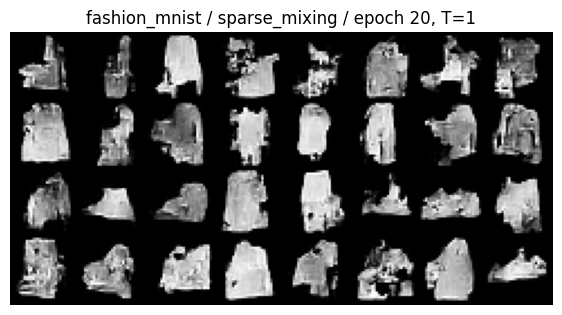

fashion_mnist | sparse_mixing | 21/40 | train 3.2623, val 3.2984 bpd | 32.1s
fashion_mnist | sparse_mixing | 22/40 | train 3.2448, val 3.2416 bpd | 32.1s
fashion_mnist | sparse_mixing | 23/40 | train 3.2304, val 3.2600 bpd | 32.3s
fashion_mnist | sparse_mixing | 24/40 | train 3.2216, val 3.2168 bpd | 33.1s
fashion_mnist | sparse_mixing | 25/40 | train 3.2102, val 3.2270 bpd | 33.5s
fashion_mnist | sparse_mixing | 26/40 | train 3.2070, val 3.2431 bpd | 32.9s
fashion_mnist | sparse_mixing | 27/40 | train 3.1991, val 3.2135 bpd | 32.0s
fashion_mnist | sparse_mixing | 28/40 | train 3.2016, val 3.2125 bpd | 32.3s
fashion_mnist | sparse_mixing | 29/40 | train 3.1952, val 3.2241 bpd | 32.5s
fashion_mnist | sparse_mixing | 30/40 | train 3.1825, val 3.1935 bpd | 33.6s


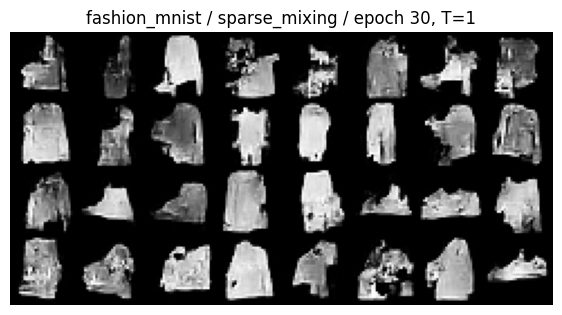

fashion_mnist | sparse_mixing | 31/40 | train 3.1792, val 3.2006 bpd | 32.7s
fashion_mnist | sparse_mixing | 32/40 | train 3.1734, val 3.1873 bpd | 32.3s
fashion_mnist | sparse_mixing | 33/40 | train 3.1700, val 3.1851 bpd | 32.0s
fashion_mnist | sparse_mixing | 34/40 | train 3.1662, val 3.1865 bpd | 32.4s
fashion_mnist | sparse_mixing | 35/40 | train 3.1626, val 3.1807 bpd | 33.0s
fashion_mnist | sparse_mixing | 36/40 | train 3.1603, val 3.1810 bpd | 32.8s
fashion_mnist | sparse_mixing | 37/40 | train 3.1588, val 3.1772 bpd | 32.6s
fashion_mnist | sparse_mixing | 38/40 | train 3.1575, val 3.1763 bpd | 32.1s
fashion_mnist | sparse_mixing | 39/40 | train 3.1564, val 3.1757 bpd | 32.1s
fashion_mnist | sparse_mixing | 40/40 | train 3.1559, val 3.1754 bpd | 32.9s


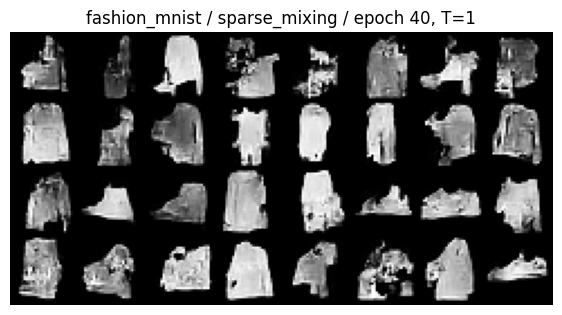

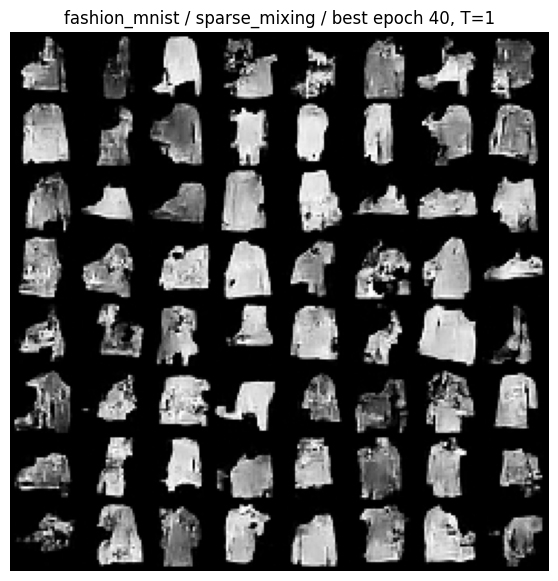

fashion_mnist | dense_mixing | 1/40 | train 5.1224, val 4.4667 bpd | 46.3s


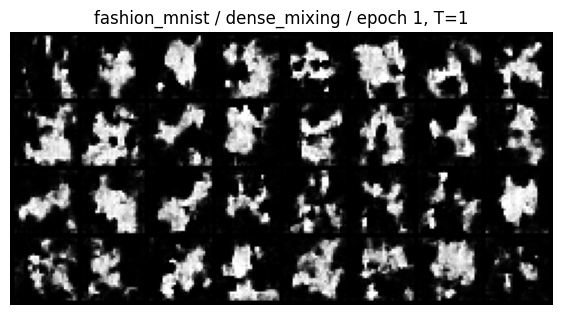

fashion_mnist | dense_mixing | 2/40 | train 4.4475, val 4.0814 bpd | 44.7s
fashion_mnist | dense_mixing | 3/40 | train 4.0344, val 3.8616 bpd | 43.6s
fashion_mnist | dense_mixing | 4/40 | train 3.8105, val 3.7950 bpd | 44.8s
fashion_mnist | dense_mixing | 5/40 | train 3.6950, val 3.6940 bpd | 47.5s
fashion_mnist | dense_mixing | 6/40 | train 3.6320, val 3.5868 bpd | 44.8s
fashion_mnist | dense_mixing | 7/40 | train 3.5207, val 3.5351 bpd | 43.9s
fashion_mnist | dense_mixing | 8/40 | train 3.4925, val 3.6937 bpd | 44.1s
fashion_mnist | dense_mixing | 9/40 | train 3.4546, val 3.4699 bpd | 46.3s
fashion_mnist | dense_mixing | 10/40 | train 3.4145, val 3.3851 bpd | 44.0s


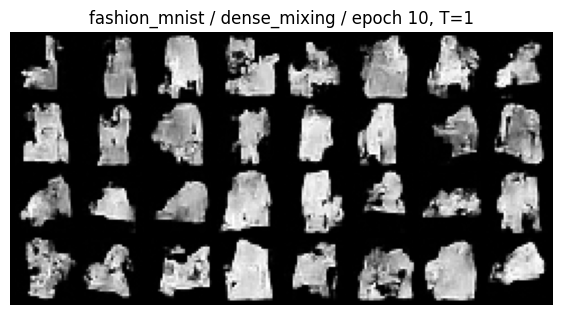

fashion_mnist | dense_mixing | 11/40 | train 3.3860, val 3.4307 bpd | 43.7s
fashion_mnist | dense_mixing | 12/40 | train 3.3850, val 3.3570 bpd | 44.1s
fashion_mnist | dense_mixing | 13/40 | train 3.3584, val 3.3165 bpd | 46.0s
fashion_mnist | dense_mixing | 14/40 | train 3.3236, val 3.3859 bpd | 44.5s
fashion_mnist | dense_mixing | 15/40 | train 3.3271, val 3.3441 bpd | 43.2s
fashion_mnist | dense_mixing | 16/40 | train 3.3085, val 3.3520 bpd | 44.0s
fashion_mnist | dense_mixing | 17/40 | train 3.2824, val 3.2937 bpd | 46.2s
fashion_mnist | dense_mixing | 18/40 | train 3.2837, val 3.2835 bpd | 44.7s
fashion_mnist | dense_mixing | 19/40 | train 3.2568, val 3.2589 bpd | 43.9s
fashion_mnist | dense_mixing | 20/40 | train 3.2451, val 3.2830 bpd | 43.5s


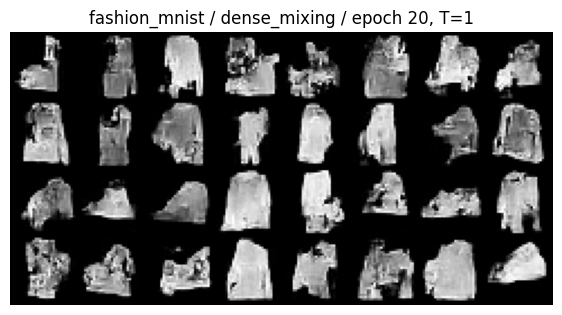

fashion_mnist | dense_mixing | 21/40 | train 3.2497, val 3.2510 bpd | 45.7s
fashion_mnist | dense_mixing | 22/40 | train 3.2374, val 3.2236 bpd | 44.3s
fashion_mnist | dense_mixing | 23/40 | train 3.2229, val 3.2210 bpd | 43.7s
fashion_mnist | dense_mixing | 24/40 | train 3.2077, val 3.2368 bpd | 43.8s
fashion_mnist | dense_mixing | 25/40 | train 3.2059, val 3.2327 bpd | 45.8s
fashion_mnist | dense_mixing | 26/40 | train 3.1981, val 3.2322 bpd | 45.1s
fashion_mnist | dense_mixing | 27/40 | train 3.1984, val 3.2563 bpd | 43.4s
fashion_mnist | dense_mixing | 28/40 | train 3.1785, val 3.1930 bpd | 44.1s
fashion_mnist | dense_mixing | 29/40 | train 3.1789, val 3.1974 bpd | 45.5s
fashion_mnist | dense_mixing | 30/40 | train 3.1685, val 3.1814 bpd | 44.5s


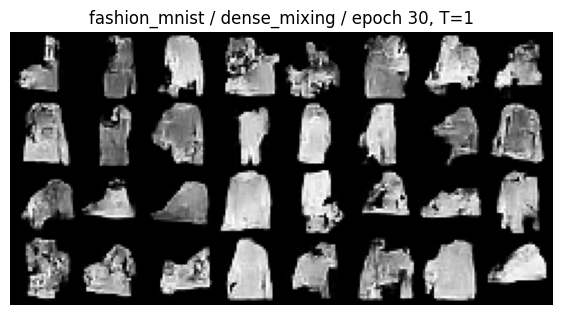

fashion_mnist | dense_mixing | 31/40 | train 3.1666, val 3.1819 bpd | 44.0s
fashion_mnist | dense_mixing | 32/40 | train 3.1633, val 3.1765 bpd | 43.8s
fashion_mnist | dense_mixing | 33/40 | train 3.1572, val 3.1755 bpd | 46.0s
fashion_mnist | dense_mixing | 34/40 | train 3.1542, val 3.1755 bpd | 44.6s
fashion_mnist | dense_mixing | 35/40 | train 3.1518, val 3.1741 bpd | 43.6s
fashion_mnist | dense_mixing | 36/40 | train 3.1497, val 3.1693 bpd | 43.7s
fashion_mnist | dense_mixing | 37/40 | train 3.1477, val 3.1683 bpd | 45.8s
fashion_mnist | dense_mixing | 38/40 | train 3.1466, val 3.1667 bpd | 44.8s
fashion_mnist | dense_mixing | 39/40 | train 3.1456, val 3.1664 bpd | 43.3s
fashion_mnist | dense_mixing | 40/40 | train 3.1451, val 3.1659 bpd | 43.8s


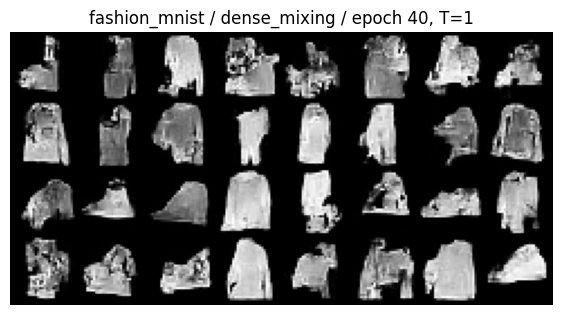

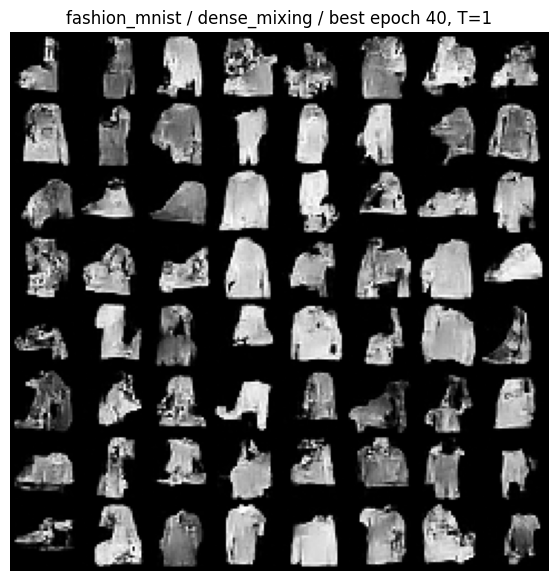

,dataset,experiment,best_epoch,val_bpd,parameters,seconds,mixing_layers,out_of_range_pixel_fraction
7,fashion_mnist,dense_mixing,40,3.165900,1615740,1783.171161,12,0.037847
5,fashion_mnist,wide_baseline,40,3.170187,1615260,1149.244825,0,0.039780
6,fashion_mnist,sparse_mixing,40,3.175409,1615340,1456.857837,2,0.040796
4,fashion_mnist,compact_baseline,35,3.433495,292712,526.382963,0,0.070372
3,mnist,dense_mixing,40,1.315428,1615740,1738.828513,12,0.042650
1,mnist,wide_baseline,40,1.322854,1615260,1552.712741,0,0.042371
2,mnist,sparse_mixing,40,1.335895,1615340,1431.784700,2,0.046177
0,mnist,compact_baseline,40,1.526617,292712,659.313609,0,0.063277


In [5]:
EXPERIMENTS=[dict(name='compact_baseline',hidden=32,depth=4,mixing='none'),
             dict(name='wide_baseline',hidden=64,depth=6,mixing='none'),
             dict(name='sparse_mixing',hidden=64,depth=6,mixing='sparse'),
             dict(name='dense_mixing',hidden=64,depth=6,mixing='dense')]
def bpd(nll): return (nll/784+math.log(256))/math.log(2)
@torch.no_grad()
def evaluate(model,loader,seed=2026):
    model.eval()
    generator=torch.Generator(device=DEVICE).manual_seed(seed)
    total,count=0.,0
    for x,_ in loader:
        nll=-model.log_prob(x.to(DEVICE),generator)
        if not torch.isfinite(nll).all(): raise FloatingPointError('Non-finite NLL')
        total+=nll.sum().item()
        count+=len(x)
    return total/count
def load_checkpoint(path): return torch.load(path,map_location=DEVICE,weights_only=True)
def new_model(spec):
    return AblationRealNVP(spec['hidden'],spec['depth'],spec['mixing']).to(DEVICE)

def train_experiment(dataset,spec):
    seed_all()
    train,val=loaders(dataset)
    model=new_model(spec)
    # Match the training noise sequence, as well as shuffled batch order.
    seed_all()
    folder=REPORT/dataset/spec['name']
    folder.mkdir(parents=True,exist_ok=True)
    checkpoint=CHECKPOINTS/f'{dataset}_{spec["name"]}.pt'
    epochs=2 if SMOKE_TEST else EPOCHS
    metadata=dict(dataset=dataset,architecture=spec,seed=SEED,epochs=epochs,
                  batch_size=BATCH_SIZE,learning_rate=LEARNING_RATE,initialization='from_scratch',
                  smoke_test=SMOKE_TEST,train_size=len(train.dataset),validation_size=len(val.dataset),
                  alpha=model.alpha,parameters=sum(p.numel() for p in model.parameters()),
                  mixing_layers=len(model.mixers),**environment)
    (folder/'config.json').write_text(json.dumps(metadata,indent=2))
    optimizer=torch.optim.Adam(model.parameters(),lr=LEARNING_RATE)
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=epochs,eta_min=1e-6)
    best,history=float('inf'),[]
    for epoch in range(1,epochs+1):
        started=time.perf_counter()
        model.train()
        total,count=0.,0
        for x,_ in train:
            x=x.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss=-model.log_prob(x).mean()
            if not torch.isfinite(loss): raise FloatingPointError('Non-finite training NLL')
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),5.,error_if_nonfinite=True)
            optimizer.step()
            total+=loss.item()*len(x)
            count+=len(x)
        val_nll=evaluate(model,val)
        row=dict(epoch=epoch,train_nll=total/count,val_nll=val_nll,
                 train_bpd=bpd(total/count),val_bpd=bpd(val_nll),
                 learning_rate=optimizer.param_groups[0]['lr'],seconds=time.perf_counter()-started)
        history.append(row)
        pd.DataFrame(history).to_csv(folder/'history.csv',index=False)
        if val_nll<best:
            best=val_nll
            torch.save(dict(model=model.state_dict(),epoch=epoch,val_nll=best,config=spec),checkpoint)
        print(f'{dataset} | {spec["name"]} | {epoch}/{epochs} | train {row["train_bpd"]:.4f}, val {row["val_bpd"]:.4f} bpd | {row["seconds"]:.1f}s',flush=True)
        if epoch==1 or epoch%10==0 or epoch==epochs:
            images,_=model.sample(n=32)
            show(images,f'{dataset} / {spec["name"]} / epoch {epoch}, T=1',folder/f'epoch_{epoch:03d}.png')
        scheduler.step()
    saved=load_checkpoint(checkpoint)
    model.load_state_dict(saved['model'])
    model.eval()
    images,outside=model.sample(n=64)
    show(images,f'{dataset} / {spec["name"]} / best epoch {saved["epoch"]}, T=1',folder/'best_samples.png')
    return dict(dataset=dataset,spec=spec,experiment=spec['name'],checkpoint=str(checkpoint),folder=str(folder),
                best_epoch=saved['epoch'],val_bpd=bpd(best),parameters=metadata['parameters'],
                seconds=sum(r['seconds'] for r in history),mixing_layers=metadata['mixing_layers'],
                out_of_range_pixel_fraction=outside)
def public_row(run):
    return {key:value for key,value in run.items() if key not in ('spec','checkpoint','folder')}
runs=[]
for dataset in ACTIVE_DATASETS:
    for spec in EXPERIMENTS:
        runs.append(train_experiment(dataset,spec))
        pd.DataFrame([public_row(run) for run in runs]).to_csv(REPORT/'validation_comparison.csv',index=False)
summary=pd.DataFrame([public_row(run) for run in runs])
display(summary.sort_values(['dataset','val_bpd']))

## 5. Learning curves and test results

Solid lines show validation bpd; dashed lines show training bpd. The curves show convergence and the gap between training and validation. For each dataset, the model with the best validation bpd was evaluated on the official test set.


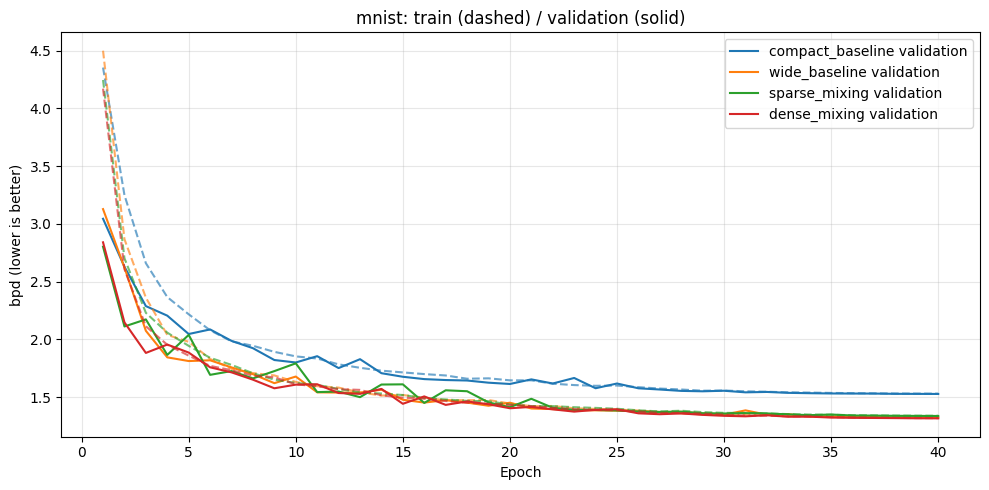

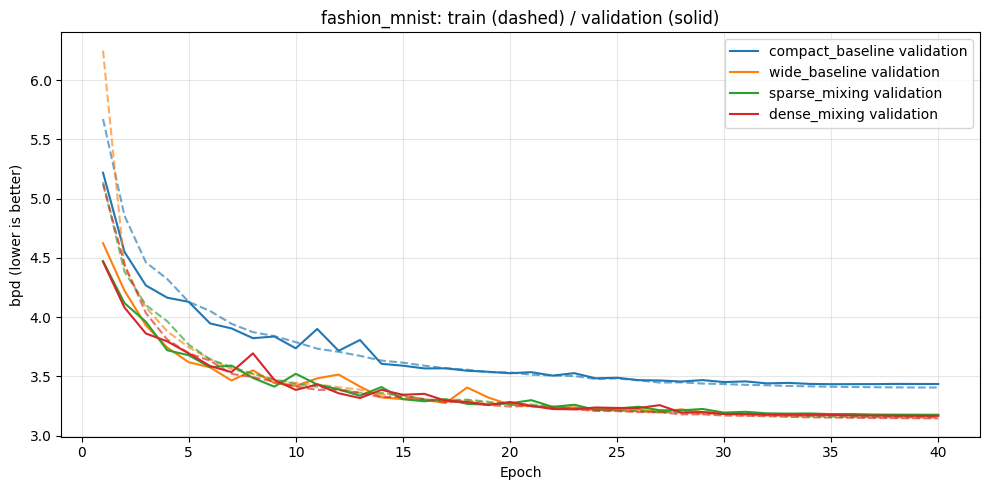

,dataset,experiment,val_bpd,test_nll,test_bpd,out_of_range_pixel_fraction,smoke_test
0,mnist,dense_mixing,1.315428,-3633.747711,1.313278,0.042650,False
1,fashion_mnist,dense_mixing,3.165900,-2625.817581,3.168043,0.037847,False


In [6]:
for dataset in ACTIVE_DATASETS:
    fig,ax=plt.subplots(figsize=(10,5))
    for run in (r for r in runs if r['dataset']==dataset):
        history=pd.read_csv(Path(run['folder'])/'history.csv')
        line,=ax.plot(history.epoch,history.val_bpd,label=run['experiment']+' validation')
        ax.plot(history.epoch,history.train_bpd,'--',color=line.get_color(),alpha=0.65)
    ax.set(title=dataset+': train (dashed) / validation (solid)',xlabel='Epoch',ylabel='bpd (lower is better)')
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(REPORT/f'{dataset}_learning_curves.png',dpi=120)
    plt.show()
    plt.close(fig)

winners={}
test_rows=[]
for dataset in ACTIVE_DATASETS:
    selected=min((r for r in runs if r['dataset']==dataset),key=lambda r:r['val_bpd'])
    winners[dataset]=selected
    model=new_model(selected['spec'])
    model.load_state_dict(load_checkpoint(Path(selected['checkpoint']))['model'])
    nll=evaluate(model,test_loader(dataset),seed=2027)
    generated,outside=model.sample(n=64,temperature=1.)
    test_rows.append(dict(dataset=dataset,experiment=selected['spec']['name'],
                          val_bpd=selected['val_bpd'],test_nll=nll,test_bpd=bpd(nll),
                          out_of_range_pixel_fraction=outside,smoke_test=SMOKE_TEST))
test_results=pd.DataFrame(test_rows)
test_results.to_csv(REPORT/'test_results.csv',index=False)
display(test_results)

## 6. Real images and generated samples

The panels compare real validation images with each experiment's best-validation checkpoint. All experiments use the same latent seeds and temperature 1. The validation winner is marked BEST. The final comparison also includes temperature 0.7, which changes the sampling distribution rather than improving likelihood.

These are unconditional samples, not reconstructions of the displayed real images. Dense mixing had the best validation bpd on both datasets. Some generated images remain ambiguous or have broken strokes, so the likelihood improvement did not solve every visual problem.


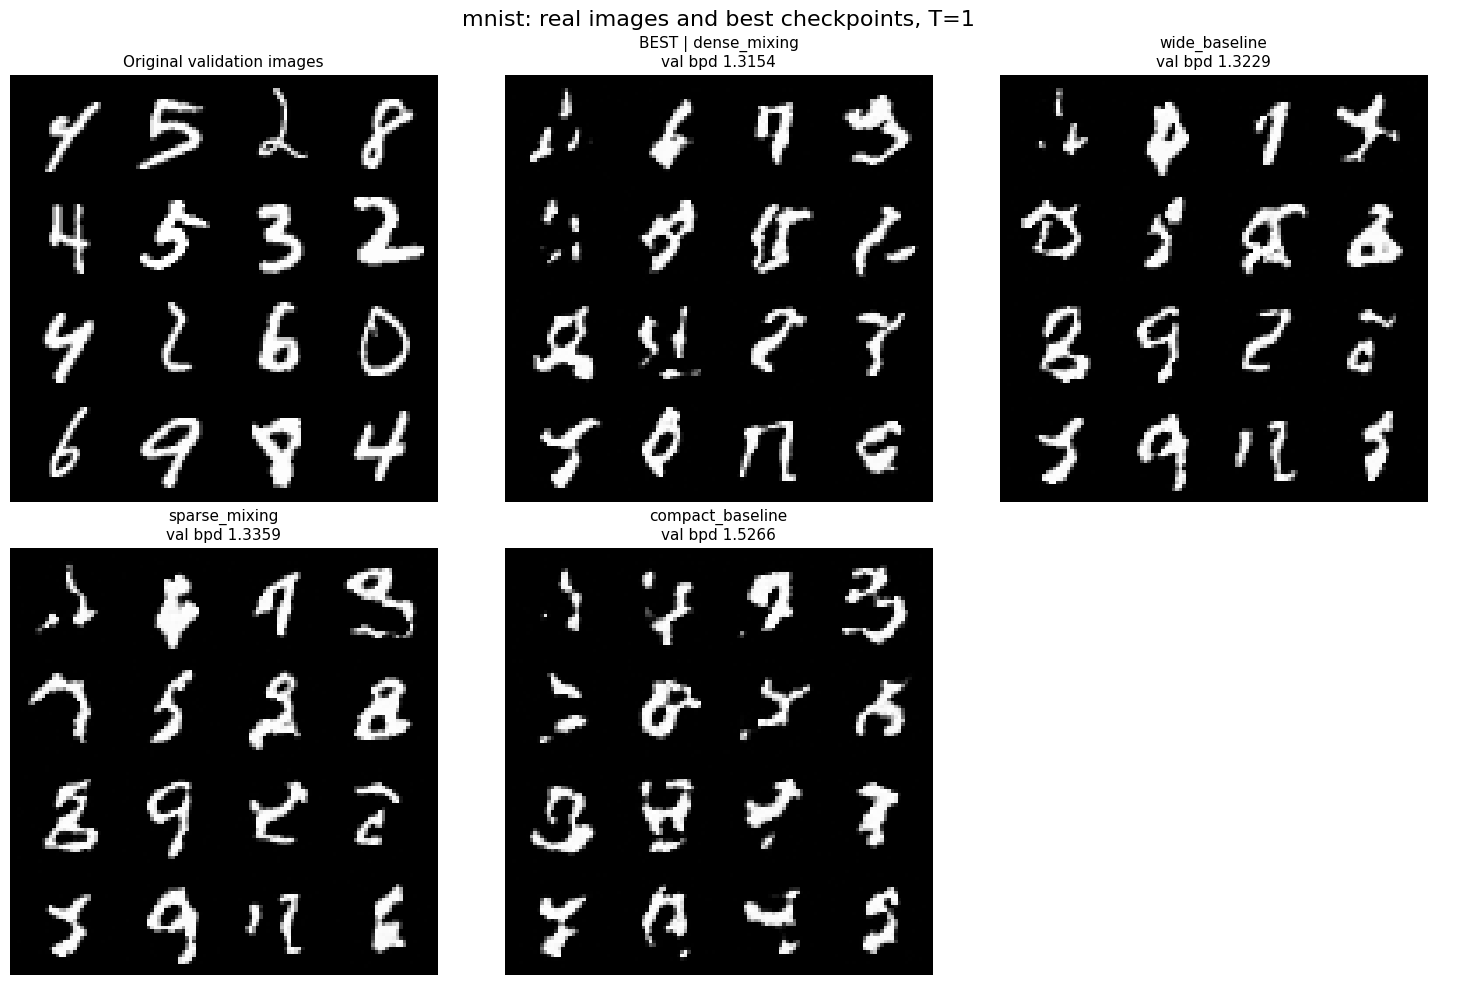

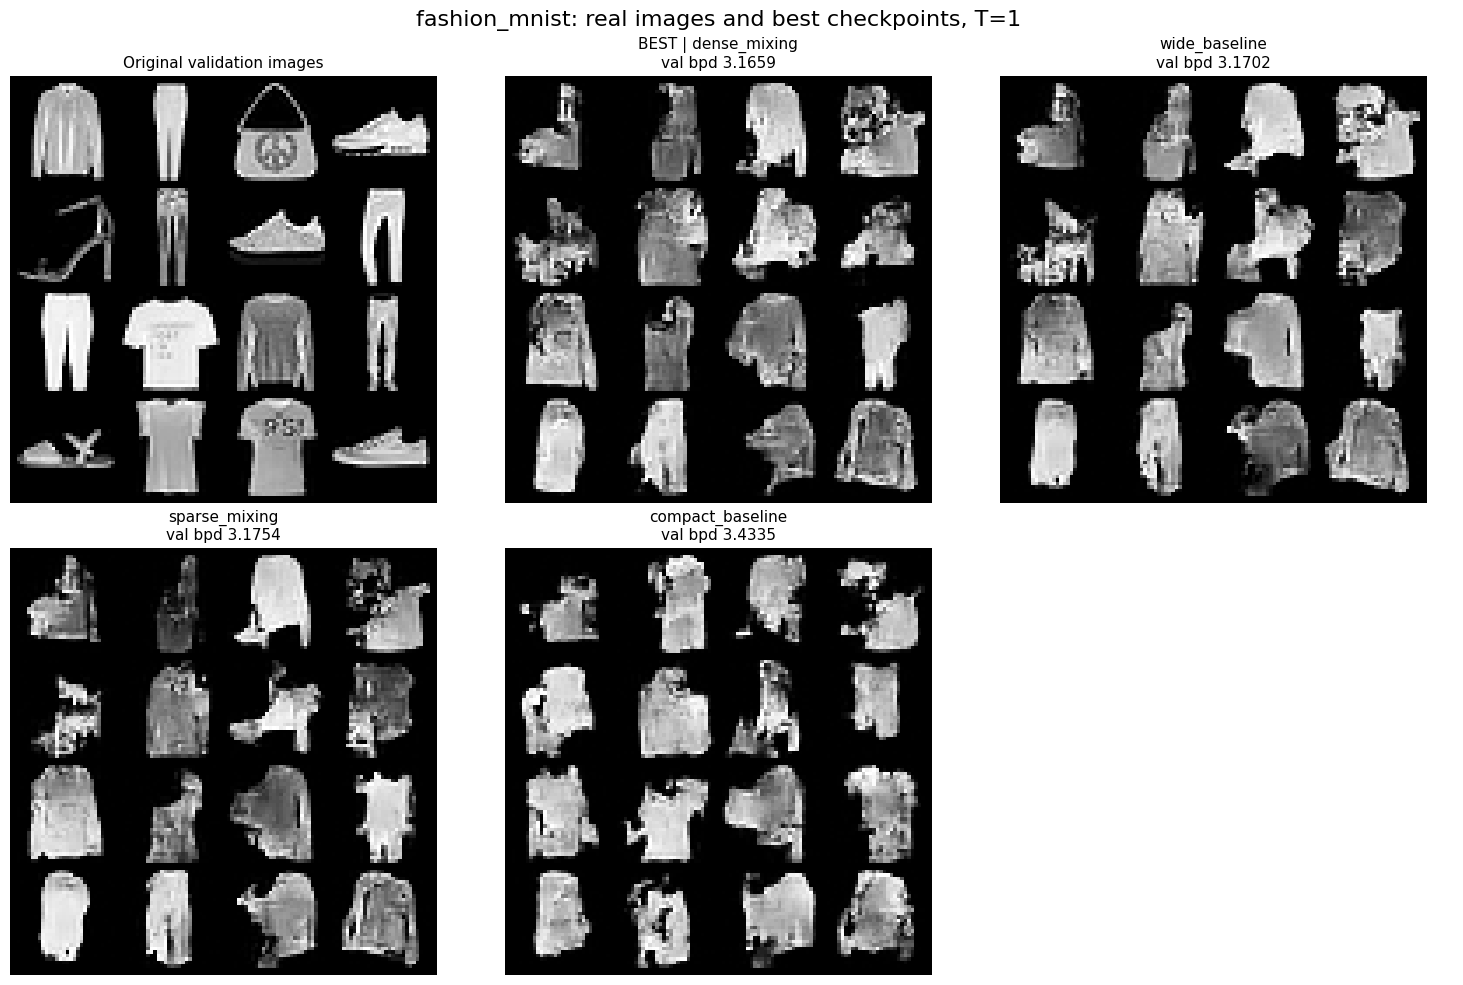

In [8]:
for dataset in ACTIVE_DATASETS:
    selected=winners[dataset]
    ordered=sorted((r for r in runs if r['dataset']==dataset),key=lambda r:r['val_bpd'])
    panels=[('Original validation images',next(iter(loaders(dataset)[1]))[0][:16])]
    for run in ordered:
        model=new_model(run['spec'])
        model.load_state_dict(load_checkpoint(Path(run['checkpoint']))['model'])
        model.eval()
        images,_=model.sample(n=64,temperature=1.)
        marker='BEST | ' if run['spec']['name']==selected['spec']['name'] else ''
        panels.append((f'{marker}{run["spec"]["name"]}\\nval bpd {run["val_bpd"]:.4f}',images[:16]))
    columns=3
    rows=math.ceil(len(panels)/columns)
    fig,axes=plt.subplots(rows,columns,figsize=(5*columns,5*rows),squeeze=False)
    for ax in axes.flat: ax.axis('off')
    for ax,(title,images) in zip(axes.flat,panels):
        grid=make_grid(images.detach().cpu(),nrow=4)
        ax.imshow(grid.permute(1,2,0).numpy(),vmin=0,vmax=1)
        ax.set_title(title.replace('\\n','\n'),fontsize=11)
    fig.suptitle(('SMOKE TEST ONLY | ' if SMOKE_TEST else '')+dataset+': real images and best checkpoints, T=1',fontsize=16)
    fig.tight_layout()
    fig.savefig(REPORT/f'{dataset}_all_experiments.png',dpi=150,bbox_inches='tight')
    plt.show()
    plt.close(fig)


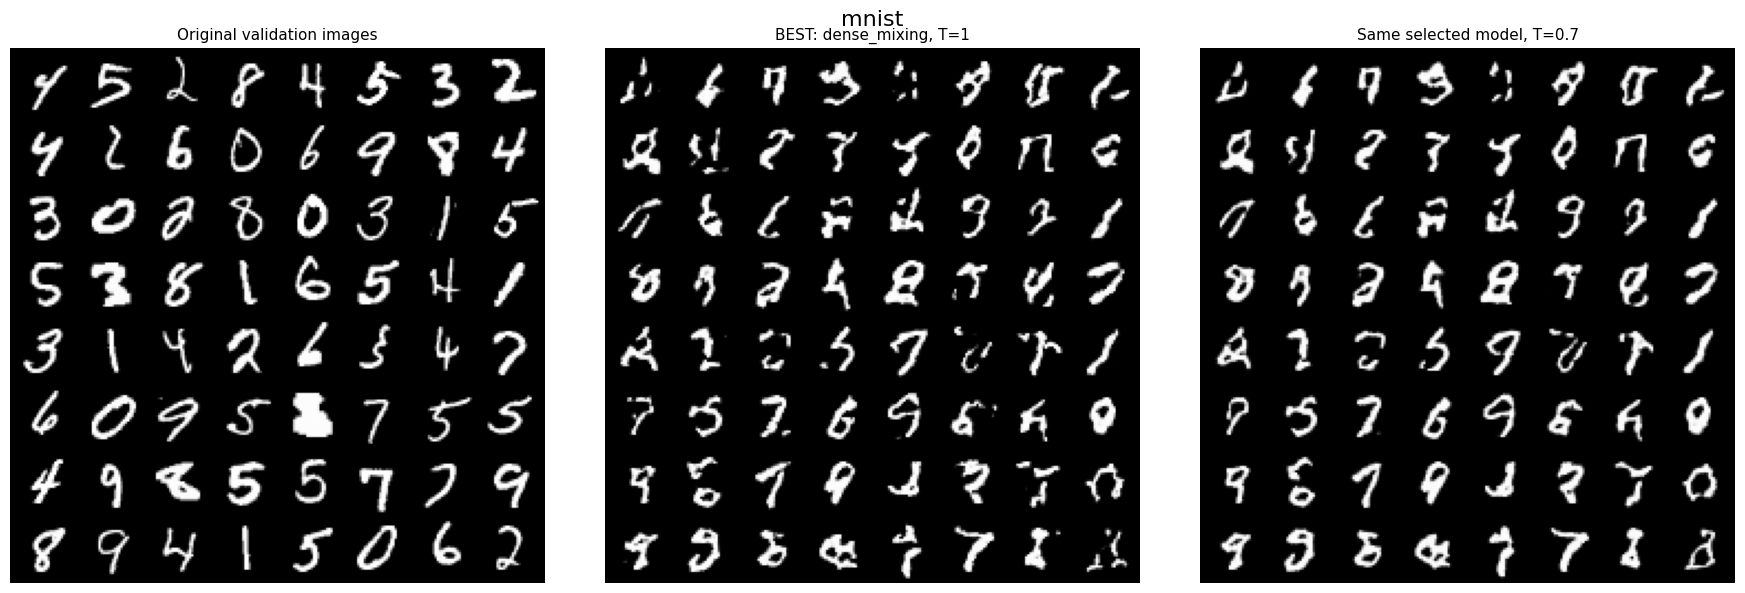

mnist: selected dense_mixing; out-of-range before clipping T=1: 4.26%, T=0.7: 0.54%


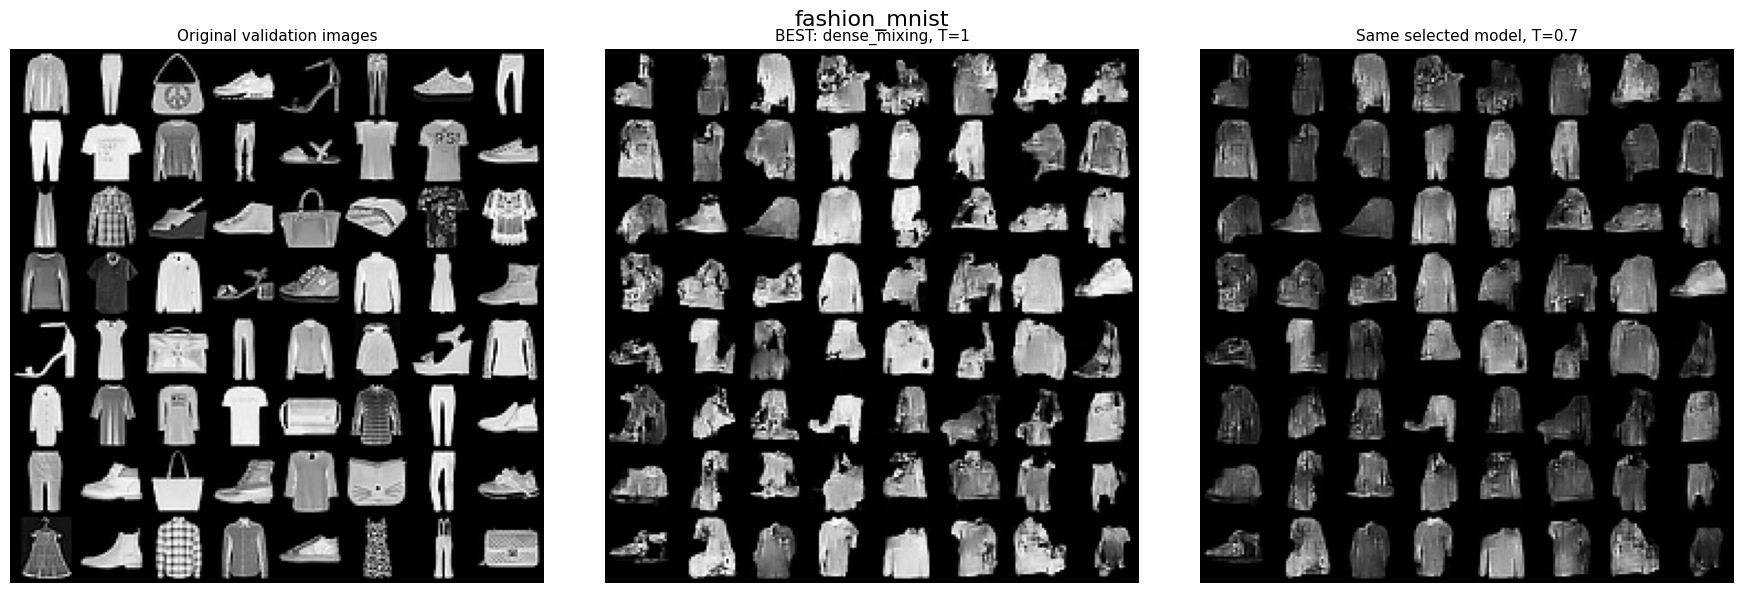

fashion_mnist: selected dense_mixing; out-of-range before clipping T=1: 3.78%, T=0.7: 0.84%
All artifacts and the English report: c:\Users\Admin\Desktop\GEN_AI_CV\HW1\results\full\20261112T152734929186Z


In [9]:
# Final output: original images beside the selected model at two sampling temperatures.
for dataset in ACTIVE_DATASETS:
    selected=winners[dataset]
    model=new_model(selected['spec'])
    model.load_state_dict(load_checkpoint(Path(selected['checkpoint']))['model'])
    model.eval()
    real=next(iter(loaders(dataset)[1]))[0][:64]
    images_t1,outside_t1=model.sample(n=64,temperature=1.)
    images_t07,outside_t07=model.sample(n=64,temperature=0.7)
    fig,axes=plt.subplots(1,3,figsize=(18,6))
    for ax,images,title in zip(axes,[real,images_t1,images_t07],
            ['Original validation images',f'BEST: {selected["spec"]["name"]}, T=1','Same selected model, T=0.7']):
        ax.imshow(make_grid(images.detach().cpu()).permute(1,2,0).numpy(),vmin=0,vmax=1)
        ax.set_title(title,fontsize=11)
        ax.axis('off')
    fig.suptitle(('SMOKE TEST ONLY | ' if SMOKE_TEST else '')+dataset,fontsize=16)
    fig.tight_layout()
    fig.savefig(REPORT/f'{dataset}_original_and_best.png',dpi=150,bbox_inches='tight')
    plt.show()
    plt.close(fig)
    print(f'{dataset}: selected {selected["spec"]["name"]}; out-of-range before clipping T=1: {outside_t1:.2%}, T=0.7: {outside_t07:.2%}')
print('All artifacts and the English report:',REPORT)
